# Модель предсказания возраста посетителей сайта
- Автор: Серов Константин
- Дата: 31.10.2026

## 1. Цель
Построение модели многоклассовой классификации, которая по цифровому следу анонимного пользователя определяет его возрастную категорию, чтобы рекламодатели могли показывать объявления нужной аудитории. 

## 2. Данные
Компания "Йети" предоставила шесть таблиц с информацией о пользователях рекламной сети РСЙ. Данные собраны из разных источников: журнала посещений сайтов и систем, фиксирующих поведенческие характеристики пользователей. 

Что важно знать про данные:
- **Формат данных.** Данные представлены в виде шести отдельных CSV-файлов, которые до моделирования не объединены. Для обучения модели их нужно собрать в единое признаковое пространство где одна строка соответствует одному пользователю.
- **Структура.** Связующий ключ во всех таблицах - `user_id`. Таблица посещений представляет собой журнал посещений. На одного пользователя приходится много строк. Остальные таблицы содержат по одной характеристике на пользователя.
- **Полнота.** Источники разные, поэтому пользователь может отсутствовать в части таблиц.
- **Данные анонимизированы.** Пользователи представлены только идентификаторами, категории сайтов закодированы анонимными названиями.

**Таблицы и признаки:**

Пользователи и целевая переменная (`ds_s13_users.csv`):
- `user_id` — уникальный идентификатор пользователя;
- `age_category` — возрастная категория пользователя (целевая переменная).

Журнал посещений (`ds_s13_visits.csv`):
- `date` — дата посещения;
- `daytime` — время суток посещения: утро, день, вечер, ночь;
- `session_id` — идентификатор сессии;
- `user_id` — идентификатор пользователя;
- `website_category` — анонимизированная категория посещённого сайта (несколько десятков категорий).

Активность по рекламе (`ads_activity.csv`):
- `user_id` — идентификатор пользователя;
- `ads_activity` — уровень кликабельности рекламы (CTR) у пользователя: очень редко, редко, умеренно, часто, очень часто.

Глубина просмотра (`surf_depth.csv`):
- `user_id` — идентификатор пользователя;
- `surf_depth` — глубина просмотра сайтов: поверхностно, средне, глубоко.

Основное устройство (`primary_device.csv`):
- `user_id` — идентификатор пользователя;
- `primary_device` — основное устройство, с которого пользователь выходит в интернет.

Облачные сервисы (`cloud_usage.csv`):
- `user_id` — идентификатор пользователя;
- `cloud_usage` — использует ли пользователь облачные сервисы: `True` / `False`.

**Целевая переменная:**

- `age_category` — возрастная категория пользователя: `0` — младше 18 лет, `1` — 18–25 лет, `2` — 26–40 лет, `3` — 41–55 лет, `4` — 56 лет и старше.

## 3. Структура проекта
1. Подготовка среды и загрузка данных;
2. Исследовательский анализ данных;
3. Предобработка данных;
4. Обучение и оценка базовой модели;
5. Создание и отбор признаков
6. Подбор гиперпараметров
7. Подготовка артефактов модели для внедрения
8. Выводы о результатах работы
---

## 4. Подготовка среды и загрузка данных

### 4.1 Подготовка библиотек
- Устанавливаем пакеты:

In [1]:
!pip install -q scikit-learn==1.6.1 phik mlxtend

- Импортируем необходимые библиотеки:

In [2]:
import sys
from datetime import datetime
from time import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import phik
import sklearn
import joblib

# Разбиение, кросс-валидация, подбор гиперпараметров
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)

# Предобработка
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

# Отбор признаков
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif, RFE
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

# Модели
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Метрики
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Многоклассовая классификация
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier

# Скрывает FutureWarning
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

In [3]:
# Версии Python и библиотек, с которыми выполнялась тетрадка
print('Python:', sys.version)
print('numpy:', np.__version__)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('matplotlib:', matplotlib.__version__)
print('seaborn:', sns.__version__)

Python: 3.9.5 | packaged by conda-forge | (default, Jun 19 2021, 00:32:32) 
[GCC 9.3.0]
numpy: 1.21.1
pandas: 1.2.4
scikit-learn: 1.6.1
matplotlib: 3.3.4
seaborn: 0.11.1


- Создадим файл `requirements.txt` с фиксированными версиями всех пакетов:

In [4]:
!pip freeze > requirements.txt

- Зафиксируем значение параметра `random_state` для воспроизводимости случайной последовательности (результата). А также настроим некоторые параметры `pandas` для удобства отображения данных.

In [5]:
# Фиксируем значение параметра random_state
RANDOM_STATE = 49

# Доля пользователей в тестовой выборке
TEST_SIZE = 0.25

# Настройка pandas
# Убираем ограничение количества отображаемых столбцов датафрейма
pd.set_option('display.max_columns', None)

---

### 4.2 Загрузка данных
- Загрузим данные датасетов

In [6]:
# Пути к данным на сервере Практикума и в открытом хранилище
SERVER_PATH = '/datasets/'
URL_PATH = 'https://code.s3.yandex.net/datasets/'

# Имена файлов по таблицам
FILES = {
    'users': 'ds_s13_users.csv',
    'visits': 'ds_s13_visits.csv',
    'ads_activity': 'ads_activity.csv',
    'surf_depth': 'surf_depth.csv',
    'primary_device': 'primary_device.csv',
    'cloud_usage': 'cloud_usage.csv',
}

# Загрузка данных
def load_data(file_name):
    # Сначала путь на сервер, при ошибке - открытое хранилище
    try:
        return pd.read_csv(SERVER_PATH + file_name)
    except FileNotFoundError:
        return pd.read_csv(URL_PATH + file_name)
    
tables = {name: load_data(file_name) for name, file_name in FILES.items()}

---

### 4.3 Знакомство с данными
- Посмотрим первые строки, типы столбцов и заполненность каждой таблицы:

In [7]:
# Размер и первые строки каждой таблицы
for name, df in tables.items():
    print(f'=== {name} ===')
    display(df.head())
    df.info()
    print()

=== users ===


,user_id,age_category
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2
2,678b-614cd47d854b9d591db2-000b2e50,0
3,4ac0-dad169100b4a29b20818-b26ae7c5,4
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5913 entries, 0 to 5912
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   user_id       5913 non-null   object
 1   age_category  5913 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 92.5+ KB

=== visits ===


,date,daytime,session_id,user_id,website_category
0,2025-11-01,вечер,066e4e02-8c1f-45eb-a50f-178659abe698,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 17
1,2025-11-01,вечер,0bce1749-3376-439c-9a22-f8ffbba00e9a,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 19
2,2025-11-01,вечер,3445d8c4-221d-4d88-bb6a-a2939fe3c610,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 18
3,2025-11-01,вечер,3bf97286-1d91-4aaa-af4a-ed58eceb8cd2,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 20
4,2025-11-01,вечер,40e22712-3cad-410d-a9f0-13bd8f6911c0,0010-5cf8f6b38a7b6c70a021-009dbcda,Category 05


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1065745 entries, 0 to 1065744
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype 
---  ------            --------------    ----- 
 0   date              1065745 non-null  object
 1   daytime           1065745 non-null  object
 2   session_id        1065745 non-null  object
 3   user_id           1065745 non-null  object
 4   website_category  1065745 non-null  object
dtypes: object(5)
memory usage: 40.7+ MB

=== ads_activity ===


,user_id,ads_activity
0,e318-d8e69c86b543a5fb927c-c36fb6e6,очень часто
1,35cd-a972339dec534f49332c-a8b6d383,редко
2,f7e6-3b29cf9cb7ed4bb00d8f-81534360,очень редко
3,5186-e25a37549e50f45b2b43-178eaabe,умеренно
4,febd-077f277466253ee04ef6-42656680,умеренно


... (3 outputs left out)

,user_id,primary_device
0,d602-ec060db7597a6b8cd4e7-aa625896,смартфон
1,9204-9558455be649d4e77945-b5e25d62,ПК
2,5eea-22babd6a9474b43b9d0b-a39a4cf2,ноутбук
3,c142-0296948e8d08e417de10-2da9523c,смартфон
4,abec-bb4092da51eb2233a928-e44ba074,ПК


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5669 entries, 0 to 5668
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   user_id         5669 non-null   object
 1   primary_device  5669 non-null   object
dtypes: object(2)
memory usage: 88.7+ KB

=== cloud_usage ===


,user_id,cloud_usage
0,a1e4-91c8a52eb855595e653f-298ce305,False
1,db9a-7b8e9e94448b7fcb19b6-4edca15f,False
2,0d55-9ad768879e9b08ca7ff9-843f76c7,True
3,4baa-43285d10a6d3cc969f2a-b21881d1,False
4,b8cd-cbb2411db005115ca64d-32700c62,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5680 entries, 0 to 5679
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      5680 non-null   object
 1   cloud_usage  5680 non-null   bool  
dtypes: bool(1), object(1)
memory usage: 50.0+ KB



- Сводка по таблицам: число строк, уникальных пользователей, пропуски и дубликаты:

In [8]:
# Сводка по таблицам
summary = pd.DataFrame({
    name: {
        'строк': len(df),
        'уникальных user_id': df['user_id'].nunique(),
        'пропусков': df.isna().sum().sum(),
        'полных дубликатов': df.duplicated().sum(),
        'доля полных дубликатов, %': round(df.duplicated().sum() / len(df) * 100 , 2), 
        'повторов user_id': df['user_id'].duplicated().sum(),
    }
    for name, df in tables.items()
}).T

display(summary)

,строк,уникальных user_id,пропусков,полных дубликатов,"доля полных дубликатов, %",повторов user_id
users,5913.0,5826.0,0.0,87.0,1.47,87.0
visits,1065745.0,5826.0,0.0,15750.0,1.48,1059919.0
ads_activity,5826.0,5593.0,0.0,233.0,4.00,233.0
surf_depth,5715.0,5715.0,0.0,0.0,0.00,0.0
primary_device,5669.0,5669.0,0.0,0.0,0.00,0.0
cloud_usage,5680.0,5680.0,0.0,0.0,0.00,0.0


Все шесть таблиц загрузились, названия столбцов совпадают с описанием. Пропусков в таблицах нет. 
- столбец `date` прочитан как `object` и потребует преобразования в `date`;
- в `users` 87 повторов (около 1.5%) `user_id`, и все они являются полными дубликатами. Их нужно будет удалить. После удаления останется 5826 пользователей без противоречий в целевой переменной;
- в `ads_activity` аналогично: 233 полных дубликата (4%), уникальных пользователей 5593;
- в журнале `visits` 1 065 745 строк, из них 15 750 полных дубликатов (около 1.5%), около 183 записей на пользователя. 

Справочные таблицы содержат данные не обо всех пользователях. При объединении таблиц у этих пользователей появятся пропуски, которые нужно будет обработать на этапе предобработки.

---

## 5. Исследовательский анализ данных

### 5.1 Базовая информация
Мы посмотрели типы данных столбцов (`dtype`). Тип данных не всегда совпадает с типом признака по смыслу. Например, в целочисленном столбце могут храниться коды категорий. Чтобы это проверить, выведем для каждого столбца тип данных и число уникальных значений

In [9]:
# Тип данных и число уникальных значений в каждом столбце
for name, df in tables.items():
    print(f'=== {name} ===')
    display(pd.DataFrame({
        'dtype': df.dtypes,
        'nunique': df.nunique()
    }).sort_values('nunique'))

=== users ===


,dtype,nunique
age_category,int64,5
user_id,object,5826


=== visits ===


,dtype,nunique
daytime,object,4
date,object,14
website_category,object,20
user_id,object,5826
session_id,object,1049995


=== ads_activity ===


,dtype,nunique
ads_activity,object,5
user_id,object,5593


... (2 outputs left out)

=== primary_device ===


,dtype,nunique
primary_device,object,4
user_id,object,5669


=== cloud_usage ===


,dtype,nunique
cloud_usage,bool,2
user_id,object,5680


Типы данных в основном соответствуют смыслу признаков:
- `cloud_usage` - логический;
- `age_category` - целочисленный код класса;
- `user_id` и `session_id` - идентификаторы. Кандидаты на удаление на этапе предобработки данных;
- остальные строковые столбцы - категориальные признаки. Число их значений совпадает с описанием, лишних вариантов написания нет;
- `ads_activity` и `surf_depth` порядковые, стоит учесть при кодировании.

Столбец `date` прочитан как `object`, для смысловой интерпретации лучше перевести в дату. Журнал охватывает 14 дней.

Всего 20 категорий сайтов. Число уникальных сессий (1 049 995) меньше числа строк ровно на число полных дубликатов (15 750).

**Что известно о пользователях и их активности**

- когда было посещение: дата и время суток;
- где: одна из 20 анонимизированных категорий сайтов. Смысл категорий неизвестен;
- данных о самом пользователе, кроме целевой возрастной категории, нет.

---

### 5.2 Целевая переменная
Целевая переменная `age_category` - возрастная категория пользователя, имеет 5 классов:
- 0 - младше 18 лет;
- 1 - от 18 до 25 лет;
- 2 - от 26 до 40 лет;
- 3 - от 41 до 55 лет;
- 4 - от 56 и старше.

Проверим баланс классов. Сколько пользователей в каждой категории и какую долю они составляют. От этого зависит, нужно ли учитывать дисбаланс при обучении, и как интерпретировать метрики. Основная метрика проекта (`F1 (macro)`) даёт всем классам одинаковый вес, поэтому редкий класс, предсказанный плохо, заметно снизит итоговую оценку. 

Отдельно важен класс 0 (младше 18 лет). Рекламодатели не хотят, чтобы модель завышала возраст несовершеннолетних. Важно точно определять категорию.

In [10]:
# Число и доля пользователей в каждой возрастной категории (без полных дубликатов)
target = tables['users'].drop_duplicates()['age_category']

pd.DataFrame({
    'Кол-во пользователей': target.value_counts(),
    'доля, %': (target.value_counts(normalize=True) * 100).round(2)
}).sort_index()

,Кол-во пользователей,"доля, %"
0,853,14.64
1,514,8.82
2,1439,24.70
3,1254,21.52
4,1766,30.31


Визуализируем распределение, построив диаграмму:

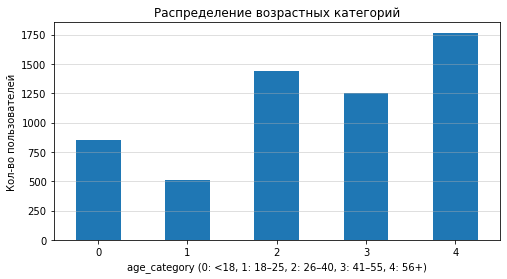

In [11]:
# Распределение возрастных категорий
target.value_counts().sort_index().plot(kind='bar', rot=0, figsize=(8, 4))
plt.title('Распределение возрастных категорий')
plt.xlabel('age_category (0: <18, 1: 18–25, 2: 26–40, 3: 41–55, 4: 56+)')
plt.ylabel('Кол-во пользователей')
plt.grid(axis='y', alpha=0.5)
plt.show()

Классы распределены неравномерно, но без явного дисбаланса. Поэтому при разбиении и кросс-валидации будем использовать стратификацию по цели. Иначе в каком-нибудь фолде может оказаться заметно меньше редкого класса 
- самый частый - 4 (56+, 30.31%), самый редкий - 1 (18-25, 8.82%). Разница примерно в 3.5 раза;
- класс 0 (младше 18), важный для бизнеса, составляет 14.64%

При обучении стоит проверить `class_weight='balanced'`, он поднимает вес редких классов, а это важно для `F1 (macro)`.

---

### 5.3 Анализ признаков
Определим, все ли признаки нужны для обучения модели.

Для начала проверим признаки на соответствие трём критериям:
- **Константный** признак принимает одно значение и не различает объекты. 
- **Квази-константный** почти всегда принимает одно значение, поэтому несёт мало информации. 
- **Уникальный признак**, наоборот, у каждой строки свой: модели не на чем обобщать, и она может только запомнить обучающие строки. Для этого считаем по каждому столбцу долю уникальных значений и долю самого частого значения.

In [12]:
# Доля уникальных значений и доля самого частого значения по каждой таблице
for name, df in tables.items():
    df_unique = df.drop_duplicates()
    print(f'=== {name} ===')
    features_info = pd.DataFrame({
        'nunique': df_unique.nunique(),
        'unique_share': (df_unique.nunique() / len(df_unique)).round(3),
        'top_share': [round(df_unique[col].value_counts(normalize=True).iloc[0], 3) for col in df_unique.columns]
    }).sort_values('nunique', ascending=False)
    display(features_info)

=== users ===


,nunique,unique_share,top_share
user_id,5826,1.000,0.000
age_category,5,0.001,0.303


=== visits ===


,nunique,unique_share,top_share
session_id,1049995,1.000,0.000
user_id,5826,0.006,0.001
website_category,20,0.000,0.066
date,14,0.000,0.072
daytime,4,0.000,0.365


=== ads_activity ===


,nunique,unique_share,top_share
user_id,5593,1.000,0.000
ads_activity,5,0.001,0.326


... (2 outputs left out)

=== primary_device ===


,nunique,unique_share,top_share
user_id,5669,1.000,0.000
primary_device,4,0.001,0.544


=== cloud_usage ===


,nunique,unique_share,top_share
user_id,5680,1.0,0.00
cloud_usage,2,0.0,0.52


- **Константных** признаков в датасете нет. Минимальное число уникальных значений равно двум (`cloud_usage`), а доля самого частого значения ни у одного столбца не достигает 1, максимум 0.544 у `primary_device`;
- Для категориальных признаков обычно используют порог доли наиболее частого значения. Например, если один уровень встречается более чем в 90% случаев, признак можно считать **квази-константным**. Порог 0,9 ни один из признаков не превышает. Однако сейчас в справочных таблицах одна строка соответствует одному пользователю, поэтому их признаки попадут в модель в таком же виде, текущий вариант проверки для них корректен. Но в таблице `visits` строка - это посещение, а `website_category`, `daytime` и `date` станут новыми признаками только после агрегации по пользователям, поэтому их проверку на квази-константность нужно будет повторить после объединения;
- Долю **уникальных** значений 1.0 имеют столбцы `user_id` и `session_id`, так как являются идентификаторами. `user_id` - ключ объединения и агрегации.

Стоит избавиться от всех айди признаков, так как они не помогут модели предсказывать возрастную категорию на новых данных.

Модель будет обучаться на данных о пользователях, поэтому шесть таблиц нужно собрать в единую таблицу, где одна строка соответствует одному пользователю. Справочные таблицы присоединим по `user_id`, а журнал посещений сначала агрегируем по пользователям: посчитаем доли посещений по категориям сайтов и по времени суток, среднее число сессий в день и самое активное время суток. Объединение оформим отдельной функцией в файле `.py`. Она понадобится на этапе внедрения, чтобы так же готовить новые сырые данные. Агрегация считается по строкам каждого пользователя отдельно и не использует целевую переменную, поэтому выполнять её до разбиения на выборки безопасно.

#### Объединение таблиц в признаковое пространство пользователей

- Для начала посчитаем доли посещений по категориям сайтов:

In [13]:
# Журнал посещений без полных дубликатов
visits = tables['visits'].drop_duplicates().copy()

# Число посещений каждой категории сайтов у каждого пользователя
site_counts = visits.pivot_table(
    index='user_id', columns='website_category',
    values='session_id', aggfunc='count', fill_value=0
)

# Доля категории
site_shares = site_counts.div(site_counts.sum(axis=1), axis=0)

# Короткие имена столбцов
site_shares.columns = ['site_' + col.replace('Category ', '') for col in site_shares.columns]

print('Размер:', site_shares.shape)
display(site_shares.head().round(3))

# Проверка. Сумма долей в каждой строке должна быть равна 1
row_sums = site_shares.sum(axis=1)
print(f'Сумма долей в строке: мин {row_sums.min():.3f}, макс {row_sums.max():.3f}')

Размер: (5826, 20)


,site_01,site_02,site_03,site_04,site_05,site_06,site_07,site_08,site_09,site_10,site_11,site_12,site_13,site_14,site_15,site_16,site_17,site_18,site_19,site_20
user_id,,,,,,,,,,,,,,,,,,,,
0010-5cf8f6b38a7b6c70a021-009dbcda,0.029,0.000,0.062,0.042,0.033,0.053,0.048,0.075,0.024,0.040,0.057,0.079,0.022,0.035,0.027,0.060,0.051,0.079,0.092,0.092
0013-4ae5f7d127b91a3fb0f8-ba59f141,0.081,0.059,0.027,0.038,0.081,0.038,0.049,0.097,0.059,0.059,0.070,0.000,0.065,0.038,0.016,0.043,0.065,0.086,0.005,0.022
0014-d3032d60979a8d2b3077-f09bdce8,0.009,0.017,0.034,0.060,0.068,0.051,0.043,0.017,0.034,0.051,0.000,0.060,0.171,0.068,0.060,0.017,0.077,0.026,0.103,0.034
001a-eee53e44f848608779b0-78704a67,0.066,0.045,0.035,0.077,0.035,0.031,0.042,0.045,0.045,0.042,0.049,0.066,0.000,0.098,0.042,0.031,0.045,0.073,0.073,0.059
002c-40a064b12e1217e12207-a56eaf3b,0.000,0.053,0.071,0.061,0.041,0.039,0.059,0.018,0.059,0.065,0.039,0.086,0.169,0.000,0.045,0.041,0.035,0.012,0.051,0.055


Сумма долей в строке: мин 1.000, макс 1.000


Доли посещений по категориям сайтов посчитаны для всех 5826 пользователей по 20 категориям. Сумма долей в каждой строке равна 1. Доли в основном близки к 0.05, поэтому различия между пользователями небольшие. Их связь с возрастом проверим после объединения таблиц.

#### Доли по времени суток и самое активное время суток
Самое активное время суток выбирается по максимальному числу посещений.

In [14]:
# Число посещений в каждое время суток у каждого пользователя
daytime_counts = visits.pivot_table(
    index='user_id', columns='daytime',
    values='session_id', aggfunc='count', fill_value=0
)

# Доля времени суток
daytime_shares = daytime_counts.div(daytime_counts.sum(axis=1), axis=0)

# Имена столбцов
daytime_shares = daytime_shares.rename(columns={
    'утро': 'daytime_morning', 'день': 'daytime_day',
    'вечер': 'daytime_evening', 'ночь': 'daytime_night'
})

# Самое активное время суток
top_daytime = daytime_counts.idxmax(axis=1).rename('top_daytime')

print('Размер:', daytime_shares.shape)
display(daytime_shares.head().round(3))

# Доля пользователей по самому активному времени суток
display(top_daytime.value_counts(normalize=True).round(3))

Размер: (5826, 4)


daytime,daytime_evening,daytime_day,daytime_night,daytime_morning
user_id,,,,
0010-5cf8f6b38a7b6c70a021-009dbcda,0.414,0.326,0.095,0.165
0013-4ae5f7d127b91a3fb0f8-ba59f141,0.276,0.373,0.086,0.265
0014-d3032d60979a8d2b3077-f09bdce8,0.308,0.385,0.094,0.214
001a-eee53e44f848608779b0-78704a67,0.415,0.334,0.108,0.143
002c-40a064b12e1217e12207-a56eaf3b,0.296,0.384,0.069,0.251


день     0.530
вечер    0.469
утро     0.001
Name: top_daytime, dtype: float64

Доли по времени суток посчитаны для всех 5826 пользователей. Основная активность приходится на день и вечер, ночью пользователи заходят реже всего. По самому активному времени суток пользователи делятся почти поровну между днём (53%) и вечером (46.9%), утро встречается у 0.1%, а ночь - ни разу. 

#### Среднее число сессий в день
Для каждого пользователя посчитаем среднее число сессий за каждый день, когда он заходил в сеть, и усредним по этим дням.

In [15]:
# Перевод даты из object в datetime
visits['date'] = pd.to_datetime(visits['date'])

# Число сессий пользователя за каждый день, когда он был активен
sessions_per_day = visits.groupby(['user_id', 'date'])['session_id'].nunique()

# Среднее число сессий в день по каждому пользователю
avg_sessions_per_day = sessions_per_day.groupby('user_id').mean().rename('avg_sessions_per_day')

print('Размер:', avg_sessions_per_day.shape)
display(avg_sessions_per_day.describe().round(2))

Размер: (5826,)


count    5826.00
mean       12.87
std         5.37
min         7.14
25%         8.86
50%        11.93
75%        15.21
max        59.93
Name: avg_sessions_per_day, dtype: float64

Добавим визуализацию, построив гистограмму распределения и диаграмму размаха:

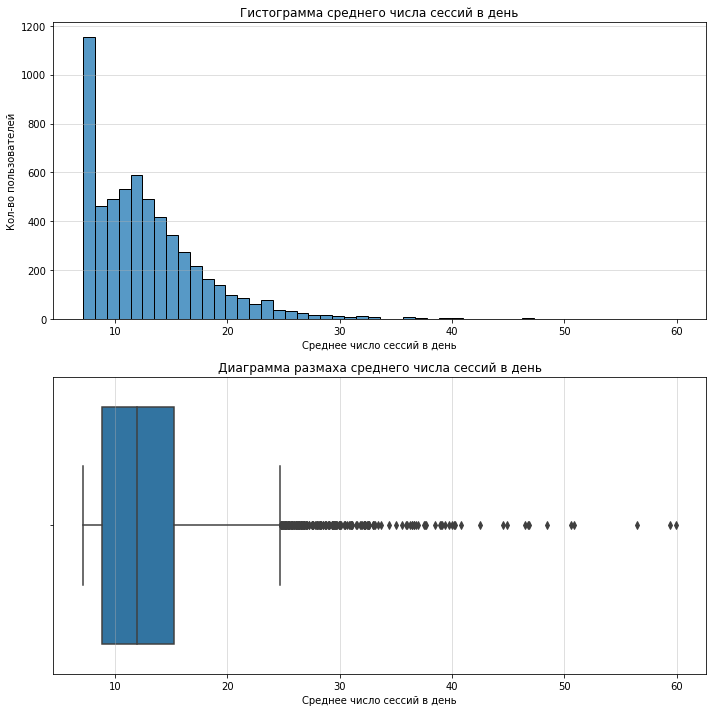

In [16]:
# Распределение среднего числа сессий в день
plt.figure(figsize=(10, 10))

# Гистограмма
plt.subplot(2, 1, 1)
sns.histplot(x=avg_sessions_per_day, bins=50)
plt.title('Гистограмма среднего числа сессий в день')
plt.xlabel('Среднее число сессий в день')
plt.ylabel('Кол-во пользователей')
plt.grid(axis='y', alpha=0.5)

# Диаграмма размаха
plt.subplot(2, 1, 2)
sns.boxplot(x=avg_sessions_per_day)
plt.title('Диаграмма размаха среднего числа сессий в день')
plt.xlabel('Среднее число сессий в день')
plt.grid(axis='x', alpha=0.5)
plt.tight_layout()

plt.show()

Распределение среднего числа сессий в день скошено вправо и имеет два пика:
- первый высокий и узкий пик у минимального значения (около 7-8 сессий);
- основной горб около 10-14 сессий, после которого идёт длинный хвост до 60;

Значения выше верхней границы межквартильного размаха выглядят как естественное поведение очень активных пользователей, поэтому удалять их пока не будем. Причину пика у минимума и связь признака с возрастом проверим после объединения таблиц, а решение по обработке выбросов примем на этапе предобработки.

#### Функция объединения
Упаковываем предыдущие шаги в функцию `build_features` в модуле `yeti_features.py`. Она убирает полные дубликаты, считает признаки журнала и присоединяет к таблице `users` агрегаты журнала и справочные таблицы.

In [17]:
%%writefile yeti_features.py
import pandas as pd

def build_features(tables):
    # Таблица без полных дубликатов, даты в формате date
    users = tables['users'].drop_duplicates()
    visits = tables['visits'].drop_duplicates().copy()
    visits['date'] = pd.to_datetime(visits['date'])
    
    # Доли посещений по категориям сайтов
    site_counts = visits.pivot_table(index='user_id', columns='website_category',
                                    values='session_id', aggfunc='count', fill_value=0)
    site_counts = site_counts.reindex(columns=[f'Category {i:02d}' for i in range(1, 21)], fill_value=0)
    site_shares = site_counts.div(site_counts.sum(axis=1), axis=0)
    site_shares.columns = ['site_' + col.replace('Category ', '') for col in site_shares.columns]
    
    # Доли по времени суток и самое активное время суток
    daytime_counts = visits.pivot_table(
        index='user_id', columns='daytime',
        values='session_id', aggfunc='count', fill_value=0
    )
    daytime_counts = daytime_counts.reindex(columns=['утро', 'день', 'вечер', 'ночь'], fill_value=0)

    # Доля времени суток
    daytime_shares = daytime_counts.div(daytime_counts.sum(axis=1), axis=0)

    # Имена столбцов
    daytime_shares = daytime_shares.rename(columns={
        'утро': 'daytime_morning', 'день': 'daytime_day',
        'вечер': 'daytime_evening', 'ночь': 'daytime_night'
    })

    # Самое активное время суток
    top_daytime = daytime_counts.idxmax(axis=1).rename('top_daytime')
    
    # Число сессий пользователя за каждый день, когда он был активен
    sessions_per_day = visits.groupby(['user_id', 'date'])['session_id'].nunique()
    # Среднее число сессий в день по каждому пользователю
    avg_sessions_per_day = sessions_per_day.groupby('user_id').mean().rename('avg_sessions_per_day')

    # Признаки журнала в одну таблицу
    visits_features = pd.concat(
        [site_shares, daytime_shares, top_daytime, avg_sessions_per_day], axis=1
    ).reset_index()
    
    # Присоединяем к пользователям признаки журнала и справочные таблицы
    data = users.merge(visits_features, on='user_id', how='left')
    for name in ['ads_activity', 'surf_depth', 'primary_device', 'cloud_usage']:
        data = data.merge(tables[name].drop_duplicates(), on='user_id', how='left')
        
    return data

Overwriting yeti_features.py


#### Применение функции и проверка результата
Импортируем функцию из файла, собираем таблицу и проверяем размер и пропуски.

In [18]:
from yeti_features import build_features

# Объединённая таблица
data = build_features(tables)

print('Размер:', data.shape)
print('Уникальных user_id:', data['user_id'].nunique())
display(data.head())

# Пропуски по столбцам, где они есть
missings = pd.DataFrame({
    'Кол-во пропусков': data.isna().sum(),
    'Доля, %': (data.isna().mean() * 100).round(2) 
})
display(missings[missings['Кол-во пропусков'] > 0].sort_values('Кол-во пропусков', 
                                                               ascending=False))

Размер: (5826, 32)
Уникальных user_id: 5826


,user_id,age_category,site_01,site_02,site_03,site_04,site_05,site_06,site_07,site_08,site_09,site_10,site_11,site_12,site_13,site_14,site_15,site_16,site_17,site_18,site_19,site_20,daytime_morning,daytime_day,daytime_evening,daytime_night,top_daytime,avg_sessions_per_day,ads_activity,surf_depth,primary_device,cloud_usage
0,f545-8c95aefe8d3e5548a689-a5b2fd39,4,0.064171,0.037433,0.037433,0.058824,0.101604,0.021390,0.000000,0.048128,0.101604,0.026738,0.074866,0.016043,0.032086,0.037433,0.053476,0.042781,0.058824,0.069519,0.074866,0.042781,0.229947,0.358289,0.336898,0.074866,день,13.357143,NaN,глубоко,смартфон,False
1,cb48-5a0d6cde4d86ae10637e-c8ceb6ed,2,0.063830,0.042553,0.099291,0.021277,0.056738,0.035461,0.106383,0.106383,0.042553,0.070922,0.042553,0.042553,0.035461,0.000000,0.063830,0.035461,0.035461,0.028369,0.035461,0.035461,0.177305,0.340426,0.390071,0.092199,вечер,10.071429,умеренно,средне,смартфон,False
2,678b-614cd47d854b9d591db2-000b2e50,0,0.010000,0.070000,0.000000,0.110000,0.070000,0.130000,0.000000,0.040000,0.000000,0.010000,0.030000,0.150000,0.120000,0.010000,0.020000,0.030000,0.020000,0.010000,0.110000,0.060000,0.200000,0.290000,0.380000,0.130000,вечер,7.142857,умеренно,средне,смартфон,False
3,4ac0-dad169100b4a29b20818-b26ae7c5,4,0.080645,0.004032,0.100806,0.028226,0.108871,0.048387,0.028226,0.064516,0.060484,0.000000,0.064516,0.016129,0.076613,0.020161,0.024194,0.028226,0.064516,0.133065,0.036290,0.012097,0.229839,0.439516,0.258065,0.072581,день,17.714286,редко,поверхностно,смартфон,True
4,f19b-9ac21ca973b41ecfa8c3-6a58191d,0,0.067227,0.042017,0.092437,0.033613,0.050420,0.008403,0.050420,0.067227,0.075630,0.042017,0.042017,0.126050,0.000000,0.084034,0.025210,0.025210,0.050420,0.033613,0.025210,0.058824,0.159664,0.344538,0.420168,0.075630,вечер,8.500000,очень редко,поверхностно,смартфон,True


,Кол-во пропусков,"Доля, %"
ads_activity,233,4.00
primary_device,157,2.69
cloud_usage,146,2.51
surf_depth,111,1.91


Функция `build_features` собрала шесть таблиц в единое пространство признаков: 5826 пользователей и 32 столбца, из них 30 признаков, плюс идентификатор `user_id` и целевая переменная `age_category`.

Пропуски есть только в справочных признаках: `ads_activity` 233 пропуска (4%), `primary_device` 157 пропусков (2.7%), `cloud_usage` 146 пропусков (2.5%), `surf_depth` 111 пропусков (1.9%). Заполнять пропуски будем на этапе предобработки внутри пайплайна.

На гистограмме среднего числа сессий в день был виден узкий пик у минимального значения. Проверим, не связан ли пик с тем, как собирались данные. Если в журнал попадали только пользователи минимум со 100 посещениями и все они заходили в сеть каждый день, то пик объясняется отбором данных, а не поведением пользователей.

In [19]:
# Число посещений и число активных дней у каждого пользователя
visits_per_user = visits.groupby('user_id').size()
active_days = visits.groupby('user_id')['date'].nunique()

print('Посещений на пользователя: мин', visits_per_user.min(), ', макс', visits_per_user.max())
print('Ровно 100 посещений:', (visits_per_user == 100).sum())
print('Активных дней: ', active_days.value_counts().to_dict())

Посещений на пользователя: мин 100 , макс 839
Ровно 100 посещений: 468
Активных дней:  {14: 5818, 13: 8}


Минимальное число посещений у пользователя ровно 100, максимальное 839, и почти все пользователи (5818 из 5826) активны все 14 дней журнала, ещё 8 - 13 дней. Значит, в журнал попали пользователи минимум со 100 посещениями. Ровно на пороге находятся 468 пользователей (около 8%), они и образуют основу пика. Это особенность сбора данных, а не аномалия поведения.

#### Разделение по категориям
Способ проверки признаков зависит от их типа. Константные и квази-константные числовые признаки ищут по дисперсии, а категориальные - по числу уникальных значений и доле самого частого значения. Поэтому сначала разделим признаки на группы.

Делим по смыслу, а не по типу данных (`dtype`):

In [20]:
# Идентификатор и целевая переменная
ID_COL = 'user_id'
TARGET = 'age_category'

# Числовые признаки
site_features = [col for col in data.columns if col.startswith('site_')]
daytime_features = ['daytime_morning', 'daytime_day', 'daytime_evening', 'daytime_night']
num_features = site_features + daytime_features + ['avg_sessions_per_day']

# Категориальные признаки
nominal_features = ['primary_device', 'top_daytime']
ordinal_features = ['ads_activity', 'surf_depth']
binary_features = ['cloud_usage']
cat_features = nominal_features + ordinal_features + binary_features

# Проверка
print('Числовых признаков:', len(num_features))
print('Категориальных признаков:', len(cat_features))
print('Все столбцы учтены:', set(num_features + cat_features + [ID_COL, TARGET]) == set(data.columns))

# Типы категориальных признаков после объединения
print(data[cat_features].dtypes)

Числовых признаков: 25
Категориальных признаков: 5
Все столбцы учтены: True
primary_device    object
top_daytime       object
ads_activity      object
surf_depth        object
cloud_usage       object
dtype: object


Все 30 признаков распределены по группам: 25 числовых и 5 категориальных. Вместе со служебными столбцами `user_id` и `age_category` они совпадают со столбцами объединённой таблицы.

Все категориальные признаки хранятся как `object`: `cloud_usage` перешёл из `bool` в `object` при объединении таблиц, потому что у 146 пользователей появились пропуски. Поэтому приводить типы не нужно. Порядковые признаки выделены отдельно. Это понадобится при выборе способа кодирования на этапе предобработки.

#### Первичный отбор
Проверим признаки объединённой таблицы базовыми методами фильтрации (константность, квази-константность, дубликаты, большая доля пропусков). Эти проверки не используют целевую переменную и не обучают статистики, которые потом применяются к данным, поэтому их можно выполнить на всей таблице до разбиения на выборки. Информация о тестовой части в модель не попадёт.

In [21]:
# Порог доли самого частого значения для квази-константных категориальных признаков
QUASI_THRESHOLD = 0.9

features = num_features + cat_features

# Константные числовые признаки: дисперсия равна 0
vs_constant = VarianceThreshold(threshold=0.0)
vs_constant.fit(data[num_features])
constant_num = [col for col, keep in zip(num_features, vs_constant.get_support()) if not keep]

# Константные категориальные признаки: одно уникальное значение
constant_cat = [col for col in cat_features if data[col].nunique() == 1]

# Квази-константные категориальные признаки: одно значение встречается чаще порога
quasi_cat = [col for col in cat_features
             if data[col].value_counts(normalize=True).iloc[0] > QUASI_THRESHOLD]

# Дублирующиеся признаки: транспонируем, чтобы столбцы стали строками
duplicated_cols = data[features].columns[data[features].T.duplicated()].tolist()

# Признаки с долей пропусков больше 50%
missing_cols = data[features].columns[data[features].isna().mean() > 0.5].tolist()

print('Константные числовые:', constant_num)
print('Константные категориальные:', constant_cat)
print('Квази-константные категориальные:', quasi_cat)
print('Дублирующиеся:', duplicated_cols)
print('Пропусков больше 50%:', missing_cols)

Константные числовые: []
Константные категориальные: []
Квази-константные категориальные: []
Дублирующиеся: []
Пропусков больше 50%: []


Для числовых признаков квази-константы ищут по порогу дисперсии. Проверим, что доли по времени суток в каждой строке дают в сумме 1, как и доли по категориям сайтов.

In [22]:
# Дисперсия числовых признаков по возрастанию
display(data[num_features].var().sort_values().round(4))

# Проверка: сумма долей по времени суток в каждой строке должна быть равна 1
daytime_sums = data[daytime_features].sum(axis=1)
print(f'Сумма долей по времени суток: мин {daytime_sums.min():.3f}, макс {daytime_sums.max():.3f}')

daytime_night            0.0006
site_11                  0.0007
site_04                  0.0008
site_06                  0.0008
site_09                  0.0008
site_16                  0.0008
site_15                  0.0008
site_10                  0.0008
site_19                  0.0008
site_17                  0.0008
site_20                  0.0008
site_07                  0.0009
site_05                  0.0009
site_02                  0.0009
site_14                  0.0009
site_12                  0.0009
site_01                  0.0010
site_18                  0.0010
site_08                  0.0010
daytime_morning          0.0015
daytime_day              0.0020
daytime_evening          0.0024
site_03                  0.0027
site_13                  0.0033
avg_sessions_per_day    28.8340
dtype: float64

Сумма долей по времени суток: мин 1.000, макс 1.000


Константных, квази-константных категориальных, дублирующихся признаков и признаков с большой долей пропусков нет.

Доли внутри каждой группы (`site_*` и `daytime_*`) в сумме дают 1, то есть один столбец каждой группы точно выражается через остальные. Это полная мультиколлинеарность. Учтём её на этапе отбора признаков: удалим по одной доле из каждой группы и сравним метрики на CV.

Дисперсии долей `site_*` и `daytime_*` малы (от 0.0006 у `daytime_night` до 0.0033 у `site_13`), но это следствие масштаба: доли лежат в пределах от 0 до 1, а типичные значения около 0.03–0.4. Дисперсия `avg_sessions_per_day` (28.8) на четыре порядка больше, чем у долей, поэтому перед обучением линейных моделей и SVM признаки нужно масштабировать.

#### Связь признаков с целевой переменной
Проверим, отличаются ли классы возраста `age_category` по признакам. Если распределения признака в разных классах совпадают, по нему нельзя отличить один возраст от другого. Если сдвинуты, признак может быть полезен модели.

Построим ящики с усами для каждого **числового** признака по классам возраста. Выбросы не отображаем (`showfliers=False`): доли `site_*` имеют длинные правые хвосты, и с выбросами ящики сжимаются у нуля так, что медианы не различить.

age_category,0,1,2,3,4
site_01,0.050,0.050,0.052,0.046,0.046
site_02,0.037,0.060,0.050,0.041,0.025
site_03,0.059,0.010,0.066,0.061,0.066
site_04,0.056,0.045,0.034,0.060,0.044
site_05,0.054,0.061,0.051,0.043,0.064
site_06,0.055,0.060,0.048,0.059,0.044
site_07,0.040,0.050,0.069,0.041,0.044
site_08,0.052,0.043,0.067,0.041,0.043
site_09,0.037,0.037,0.034,0.061,0.065
site_10,0.036,0.032,0.050,0.060,0.045


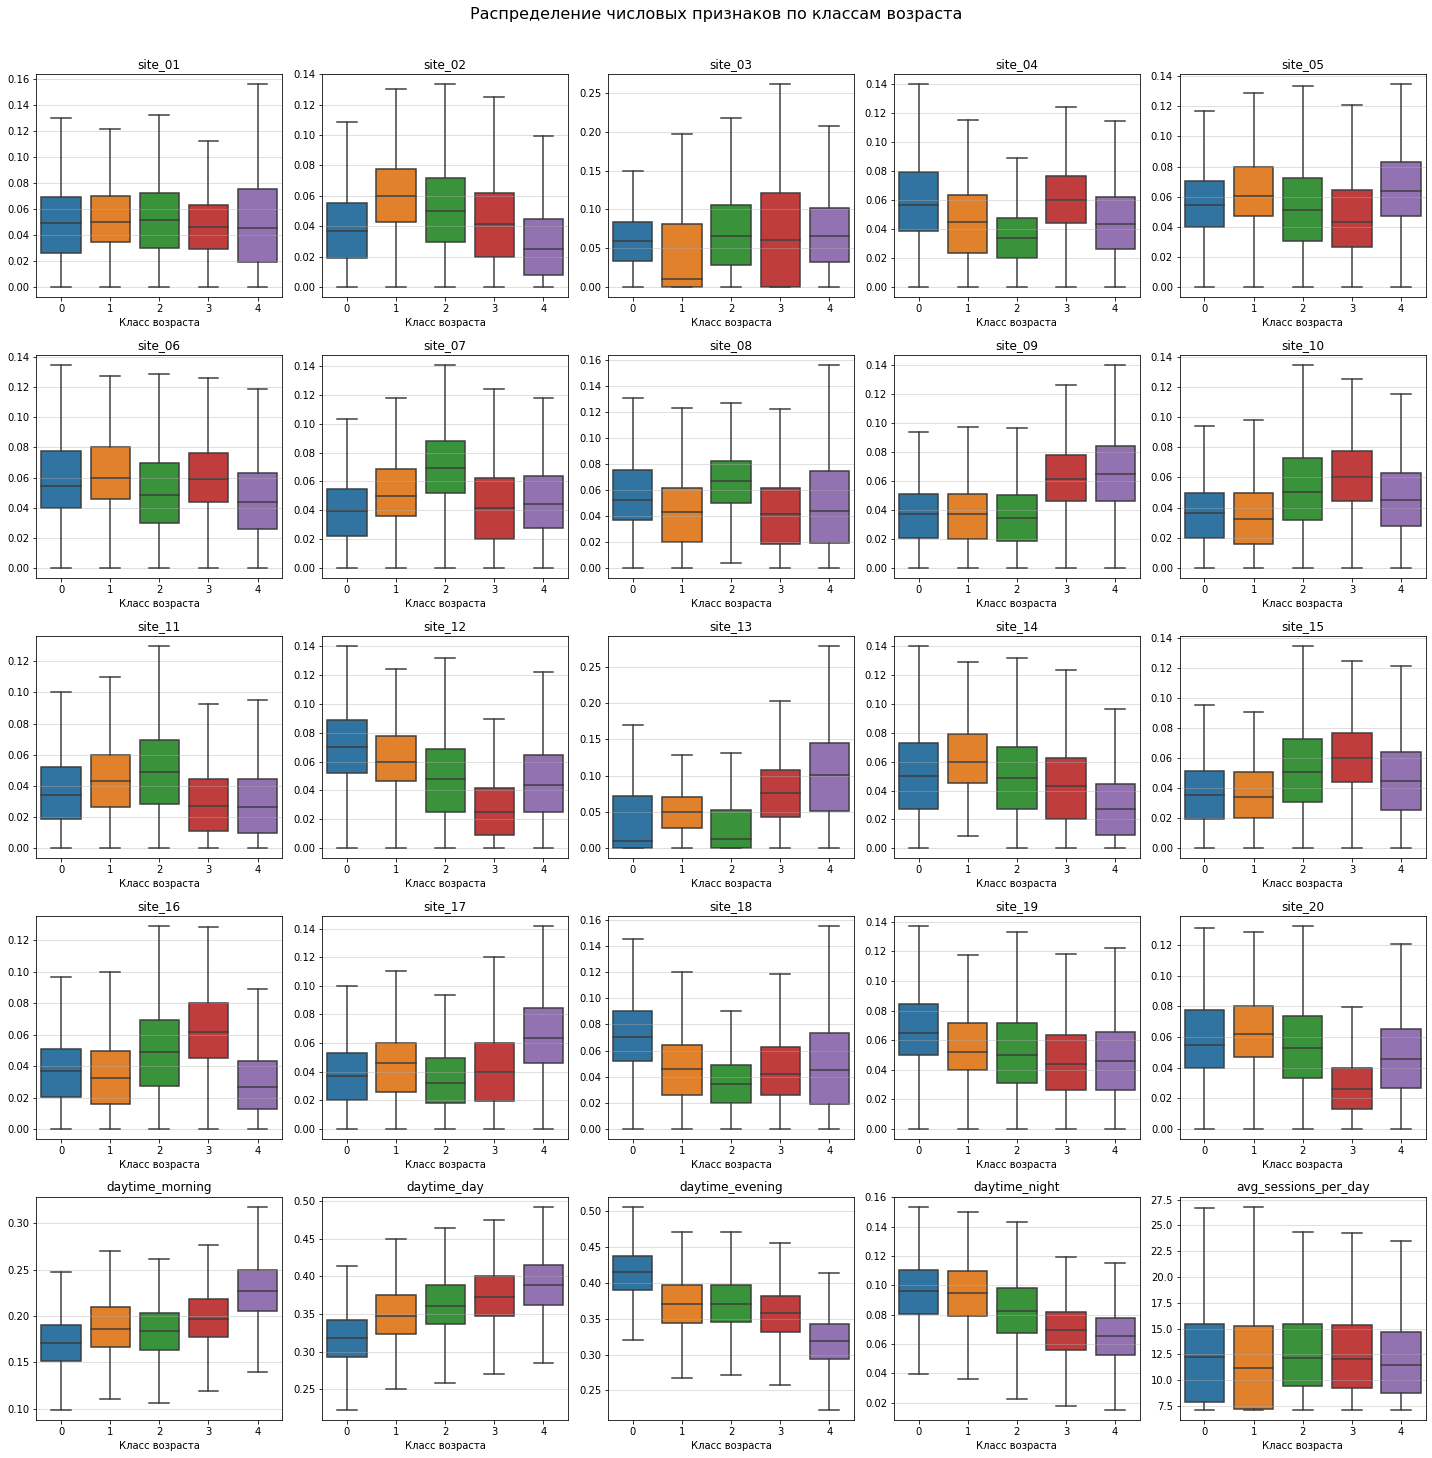

In [23]:
# Медианы числовых признаков по классам возраста
medians = data.groupby(TARGET)[num_features].median()
display(medians.T.round(3))

plt.figure(figsize=(20, 20))

for i, col in enumerate(num_features, start=1):
    plt.subplot(5, 5, i)
    # Ящик с усами по классам возраста, без отображения выбросов
    sns.boxplot(x=TARGET, y=col, data=data, showfliers=False)
    plt.grid(axis='y', alpha=0.5)
    plt.title(col)
    plt.xlabel('Класс возраста')
    plt.ylabel('')

plt.suptitle('Распределение числовых признаков по классам возраста', y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

In [24]:
# Диапазон и квартили числовых признаков
display(data[num_features].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
site_01,5826.0,0.050,0.031,0.000,0.027,0.049,0.070,0.183
site_02,5826.0,0.042,0.029,0.000,0.019,0.040,0.061,0.181
site_03,5826.0,0.065,0.052,0.000,0.020,0.060,0.102,0.261
site_04,5826.0,0.049,0.028,0.000,0.029,0.046,0.066,0.188
site_05,5826.0,0.057,0.029,0.000,0.037,0.055,0.076,0.172
site_06,5826.0,0.054,0.028,0.000,0.034,0.051,0.071,0.171
site_07,5826.0,0.051,0.029,0.000,0.030,0.050,0.070,0.165
site_08,5826.0,0.053,0.032,0.000,0.029,0.051,0.074,0.189
site_09,5826.0,0.051,0.028,0.000,0.030,0.049,0.069,0.188
site_10,5826.0,0.049,0.029,0.000,0.029,0.048,0.067,0.218


Сильнее всего классы различаются по распределению активности в течение суток, причём почти монотонно от класса 0 к классу 4: медианная доля утренних посещений растёт с 0.171 до 0.227, дневных - с 0.319 до 0.389, а доли вечерних (с 0.414 до 0.319) и ночных (с 0.096 до 0.065) посещений снижаются. Исключение - классы 1 и 2, между которыми доли утренних и вечерних посещений практически совпадают.

Доли категорий сайтов меняются не монотонно, но многие из них выделяют отдельные классы: `site_13` почти не посещают классы 0 и 2 (медиана 0.010 и 0.013 против 0.101 в классе 4), `site_03` - класс 1 (0.010 против 0.059-0.066 у остальных), `site_09` чаще посещают классы 3 и 4 (0.061-0.065 против 0.034-0.037), а `site_20` реже посещает класс 3 (0.026 против 0.045-0.062). Слабее всего классы различаются по `site_01` (медианы 0.046–0.052) и по `avg_sessions_per_day` (11.2-12.2 сессии в день при почти совпадающих ящиках).

Межквартильные размахи классов заметно перекрываются у всех признаков, поэтому ни один признак сам по себе возраст не определяет - модели понадобится их сочетание. Количественно связь с целью оценим через `phik` на обучающей выборке на этапе отбора признаков.

Для **категориальных** признаков сравним доли значений внутри каждого класса возраста: `pd.crosstab` с `normalize='index'` делит каждую строку на её сумму, поэтому доли в строке дают 1. Если столбцы на графике выглядят одинаково для всех классов, признак возраст не различает.

In [25]:
# Доли значений категориальных признаков внутри каждого класса возраста
ads = pd.crosstab(data[TARGET], data['ads_activity'], normalize='index')
surf = pd.crosstab(data[TARGET], data['surf_depth'], normalize='index')
cloud = pd.crosstab(data[TARGET], data['cloud_usage'], normalize='index')
daytime = pd.crosstab(data[TARGET], data['top_daytime'], normalize='index')
device = pd.crosstab(data[TARGET], data['primary_device'], normalize='index')

# Сводная таблица показателей для вывода
cat_summary = pd.DataFrame({
    'top_daytime: вечер': daytime['вечер'],
    'primary_device: смартфон': device['смартфон'],
    'primary_device: ПК': device['ПК'],
    'ads_activity: редко + очень редко': ads['редко'] + ads['очень редко'],
    'surf_depth: поверхностно': surf['поверхностно'],
    'cloud_usage: False': cloud[False]
}).T.round(3)

display(cat_summary)

age_category,0,1,2,3,4
top_daytime: вечер,0.897,0.603,0.541,0.385,0.130
primary_device: смартфон,0.701,0.696,0.586,0.505,0.417
primary_device: ПК,0.108,0.123,0.196,0.231,0.330
ads_activity: редко + очень редко,0.591,0.448,0.267,0.346,0.579
surf_depth: поверхностно,0.525,0.390,0.325,0.409,0.478
cloud_usage: False,0.647,0.374,0.304,0.446,0.600


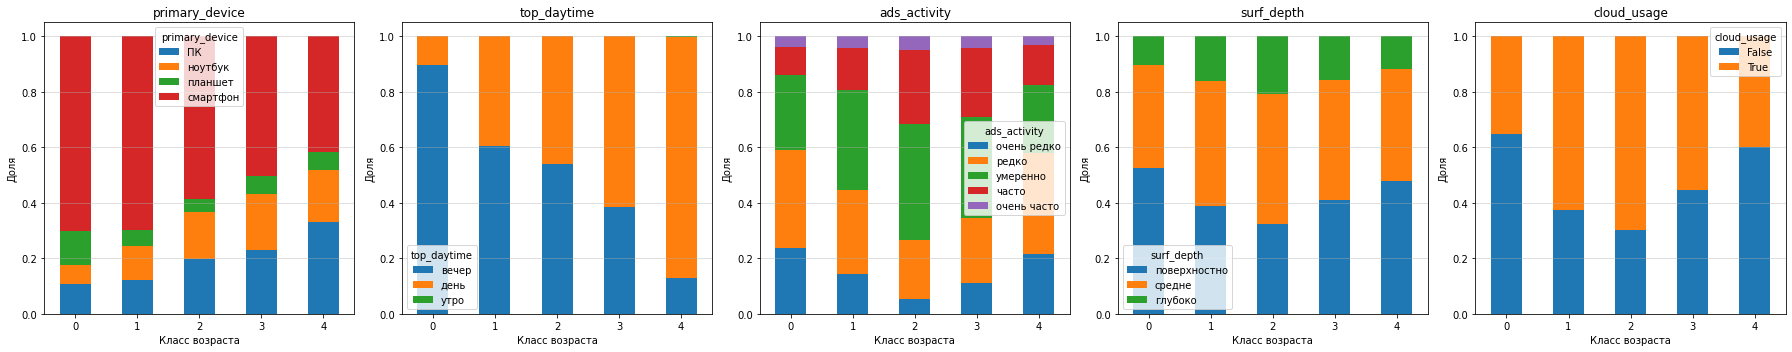

In [26]:
# Порядок значений порядковых признаков по смыслу
ordinal_order = {
    'ads_activity': ['очень редко', 'редко', 'умеренно', 'часто', 'очень часто'],
    'surf_depth': ['поверхностно', 'средне', 'глубоко']
}

fig, axes = plt.subplots(1, len(cat_features), figsize=(25, 5))

for ax, col in zip(axes, cat_features):
    # Доли значений признака внутри каждого класса возраста
    shares = pd.crosstab(data[TARGET], data[col], normalize='index')

    # Для порядковых признаков упорядочиваем столбцы по смыслу, остальные оставляем как есть
    if col in ordinal_order:
        shares = shares[ordinal_order[col]]

    shares.plot(kind='bar', stacked=True, ax=ax)
    ax.grid(axis='y', alpha=0.5)
    ax.set_title(col)
    ax.set_xlabel('Класс возраста')
    ax.set_ylabel('Доля')
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

Сильнее всего классы различает `top_daytime`: доля пользователей с преобладанием вечерних посещений монотонно снижается с 0.897 в классе 0 до 0.130 в классе 4. Это согласуется с долями `daytime_*` среди числовых признаков. Значение "утро" встречается всего у 0.1% пользователей и как отдельная категория информации почти не несёт.

`primary_device` тоже меняется монотонно: доля смартфона снижается с 0.701 в классе 0 до 0.417 в классе 4, а доля ПК растёт с 0.108 до 0.330.

`ads_activity`, `surf_depth` и `cloud_usage` меняются не монотонно, но согласованно: наиболее активен класс 2, а крайние классы 0 и 4 похожи друг на друга. В классе 2 реже всего встречается низкая рекламная активность ("редко" и "очень редко" 0.267 против 0.579-0.591 в классах 0 и 4), поверхностный просмотр (0.325 против 0.478-0.525) и отказ от облака (доля `False` 0.304 против 0.600-0.647). Такие признаки отделяют средние классы от крайних и дополняют `top_daytime` и `primary_device`, которые лучше разделяют классы 0 и 4.

---

### Вывод по исследовательскому анализу

**Качество данных.** Пропусков в исходных таблицах нет. Полные дубликаты найдены в `users` (87, 1.5%), `ads_activity` (233, 4%) и `visits` (15 750, 1.5%). Функция `build_features` их удаляет. Объединённая таблица содержит 5826 пользователей и 30 признаков (25 числовых, 5 категориальных). Пропуски появились только в справочных признаках, у пользователей, которых нет в части таблиц: от 1.9% (`surf_depth`) до 4% (`ads_activity`).

**Целевая переменная.** Классы распределены неравномерно: от 8.82% у класса 1 до 30.31% у класса 4, важный для бизнеса класс 0 составляет 14.64%. Поэтому при разбиении и кросс-валидации нужна стратификация, основная метрика - `F1 (macro)`, и стоит проверить `class_weight='balanced'`.

**Признаки.** Константных, квази-константных и дублирующихся признаков нет. Сильнее всего возраст различают распределение активности по времени суток (`top_daytime`: доля "вечер" снижается с 0.897 в классе 0 до 0.130 в классе 4) и `primary_device`. `ads_activity`, `surf_depth` и `cloud_usage` отделяют средние классы от крайних. Из категорий сайтов выделяются `site_13`, `site_03`, `site_09` и `site_20`. Слабее всего связаны с возрастом `site_01` и `avg_sessions_per_day`. Ни один признак не разделяет классы в одиночку.

**Что учесть на следующих этапах:**
- заполнить пропуски справочных признаков внутри пайплайна;
- масштабировать числовые признаки: дисперсия `avg_sessions_per_day` на четыре порядка больше, чем у долей;
- принять решение по выбросам `avg_sessions_per_day`: правый хвост до 59.9 сессий в день, а пик у минимума объясняется порогом отбора в 100 посещений;
- учесть порядок значений `ads_activity` и `surf_depth` при кодировании;
- на этапе отбора устранить полную мультиколлинеарность долей `site_*` и `daytime_*` и оценить связь признаков с целью через `phik` на обучающей выборке.

---

## Предобработка данных

### 6.1 Разделение данных
Перед предобработкой разделим данные на обучающую и тестовую выборки. Так заполнение пропусков, кодирование и масштабирование будут обучаться только на `train`, а информация из теста не попадёт в модель.
- признаки берём по списку `features` (25 числовых и 5 категориальных), целевой признак - `age_category`. `user_id` в список не входит и в модель не попадает. Столбец остаётся в `data`: `train_test_split` сохраняет номера строк, потом по ним проверим, что ни один пользователь не оказался одновременно в обеих выборках;
- в тест отправляем 25% пользователей (`TEST_SIZE`);
- стратифицируем по цели, чтобы доли классов в выборках совпадали. Это важно для редкого класса 1 (8.82%) и для класса 0 (14.64%).

In [27]:
# Матрица признаков по списку и целеая переменная
X = data[features]
y = data[TARGET]

# Разбиение со стратификацией по цели
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

# Пользователи каждой выборки: user_id из data по номерам строк
train_users = set(data.loc[X_train.index, ID_COL])
test_users = set(data.loc[X_test.index, ID_COL])

print('Признаков:', X.shape[1], ' user_id в признаках:', ID_COL in X.columns)
print('Пользователей в train:', len(train_users), ' в test:', len(test_users))
print('Общих пользователей:', len(train_users & test_users))
print(f'Доля пользователей в test: {len(test_users) / data[ID_COL].nunique():.3f}')

# Доли классов во всей выборке, в train и в test
class_shares = pd.DataFrame({
    'вся выборка, %': y.value_counts(normalize=True) * 100,
    'train, %': y_train.value_counts(normalize=True) * 100,
    'test, %': y_test.value_counts(normalize=True) * 100
}).sort_index().round(2)

display(class_shares)

Признаков: 30  user_id в признаках: False
Пользователей в train: 4369  в test: 1457
Общих пользователей: 0
Доля пользователей в test: 0.250


,"вся выборка, %","train, %","test, %"
0,14.64,14.65,14.62
1,8.82,8.83,8.79
2,24.70,24.70,24.71
3,21.52,21.52,21.55
4,30.31,30.30,30.34


Расхождений в выборках практически нет, стратификация отработала как надо.

---

### 6.2 Построение пайплайнов
#### 6.2.1 Числовые признаки

Для числовых признаков (`num_features`) пайплайн состоит из двух шагов.

- Первый шаг, `SimpleImputer` с медианой, заполняет пропуски. В текущих данных их нет: журнал посещений есть у всех пользователей. На новых данных пропуски могут появиться у пользователя без записей в журнале. Тогда все доли `site_*`, `daytime_*` и `avg_sessions_per_day` у него будут пустыми. Медиана устойчива к выбросам, а у `avg_sessions_per_day` длинный правый хвост, поэтому выбираем её.
- Второй шаг, `StandardScaler`, приводит признаки к нулевому среднему и единичному стандартному отклонению. Масштабы признаков сильно различаются: дисперсия `avg_sessions_per_day` (28.8) на четыре порядка больше, чем у долей (0.0006–0.0033). Логистическая регрессия с регуляризацией и SVM чувствительны к масштабу признаков, поэтому без масштабирования один признак подавил бы остальные.

Обработка выбросов не входит в пайплайн: это исправление самих данных, его выполняют до пайплайна. Выбросы `avg_sessions_per_day` оставляем. Значения правого хвоста (до 59.9 сессий в день) выглядят как естественное поведение очень активных пользователей. Пик у минимума объясняется порогом отбора в 100 посещений, а не ошибками в данных.

In [28]:
# Пайплайн числовых признаков
def make_num_pipeline():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

# Проверка
num_check = pd.DataFrame(
    make_num_pipeline().fit_transform(X_train[num_features]),
    columns=num_features
)

print('Размер:', num_check.shape)
display(num_check.agg(['mean', 'std']).T.round(3))

Размер: (4369, 25)


,mean,std
site_01,-0.0,1.0
site_02,0.0,1.0
site_03,-0.0,1.0
site_04,-0.0,1.0
site_05,-0.0,1.0
site_06,0.0,1.0
site_07,-0.0,1.0
site_08,-0.0,1.0
site_09,-0.0,1.0
site_10,0.0,1.0


После преобразования у всех 25 числовых признаков среднее 0, а стандартное отклонение 1. Значит, импьютер и скейлер отработали корректно.

#### 6.2.2 Категориальные признаки

Для категориальных признаков (`cat_features`) пайплайн тоже состоит из двух шагов.

- Первый шаг, `SimpleImputer` с самым частым значением (`most_frequent`), заполняет пропуски. Они есть в справочных признаках у пользователей, которых нет в части таблиц: от 1.9% (`surf_depth`) до 4% (`ads_activity`). Доля пропусков небольшая, поэтому заполнение модой почти не исказит распределения.
- Второй шаг, `OneHotEncoder`, превращает каждое значение признака в отдельный столбец из 0 и 1. Параметр `handle_unknown='ignore'` нужен для значений, которых не было при обучении. Это актуально для `top_daytime`, значение "утро" встречается у 0.1% пользователей и может не попасть в обучающий фолд кросс-валидации. `sparse_output=False` возвращает обычный массив вместо разреженной матрицы.

Порядковые `ads_activity` и `surf_depth` тоже кодируем через OHE.

In [29]:
# Пайплайн категориальных признаков
def make_cat_pipeline():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

# Проверка
cat_pipeline = make_cat_pipeline().fit(X_train[cat_features])
cat_check = pd.DataFrame(
    cat_pipeline.fit_transform(X_train[cat_features]),
    columns=cat_pipeline.get_feature_names_out(cat_features)
)

# Значения, которыми импьютер заполняет пропуски
print('Заполнение пропусков:', dict(zip(cat_features, cat_pipeline.named_steps['imputer'].statistics_)))

print('Столбцов после OHE:', cat_check.shape[1], ' ожидалось:', X_train[cat_features].nunique().sum())
print('Пропусков после преобразования:', cat_check.isna().sum().sum())
print(cat_check.columns.tolist())

Заполнение пропусков: {'primary_device': 'смартфон', 'top_daytime': 'день', 'ads_activity': 'умеренно', 'surf_depth': 'средне', 'cloud_usage': True}
Столбцов после OHE: 17  ожидалось: 17
Пропусков после преобразования: 0
['primary_device_ПК', 'primary_device_ноутбук', 'primary_device_планшет', 'primary_device_смартфон', 'top_daytime_вечер', 'top_daytime_день', 'top_daytime_утро', 'ads_activity_очень редко', 'ads_activity_очень часто', 'ads_activity_редко', 'ads_activity_умеренно', 'ads_activity_часто', 'surf_depth_глубоко', 'surf_depth_поверхностно', 'surf_depth_средне', 'cloud_usage_False', 'cloud_usage_True']


Пайплайн категориальных признаков отработал корректно: после преобразования 17 столбцов (4 + 3 + 5 + 3 + 2), как и ожидалось, пропусков не осталось. Пропуски заполняются самыми частыми значениями в train. OHE упорядочивает значения по алфавиту, а не по смыслу, но для кодирования это не важно, каждое значение получает свой столбец и свой вес в модели.

#### Объединение пайплайнов
`ColumnTransformer` применяет к каждой группе столбцов свой пайплайн и склеивает результаты в одну матрицу: числовые признаки идут через `num_pipeline`, категориальные — через `cat_pipeline`. Столбцы, которых нет ни в одном списке, по умолчанию отбрасываются (`remainder='drop'`).

Сборку оформим функцией `make_preprocessor(num_cols, cat_cols)`. На этапе отбора списки признаков будут меняться, и каждый набор получит свой препроцессор одной строкой. `make_num_pipeline` и `make_cat_pipeline` создают новый пайплайн при каждом вызове, поэтому каждый препроцессор обучается независимо от остальных.

In [30]:
# Препроцессор
def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ('num', make_num_pipeline(), num_cols),
        ('cat', make_cat_pipeline(), cat_cols)
    ])

# Препроцессор на полном наборе признаков
preprocessor = make_preprocessor(num_features, cat_features)
preprocessor.fit(X_train)
feature_names = preprocessor.get_feature_names_out()

# Проверка
print('Ожидалось столбцов:', len(num_features) + cat_check.shape[1])
print('Столбцов на выходе:', len(feature_names))

display(pd.DataFrame(preprocessor.transform(X_train.head()), columns=feature_names))

Ожидалось столбцов: 42
Столбцов на выходе: 42


,num__site_01,num__site_02,num__site_03,num__site_04,num__site_05,num__site_06,num__site_07,num__site_08,num__site_09,num__site_10,num__site_11,num__site_12,num__site_13,num__site_14,num__site_15,num__site_16,num__site_17,num__site_18,num__site_19,num__site_20,num__daytime_morning,num__daytime_day,num__daytime_evening,num__daytime_night,num__avg_sessions_per_day,cat__primary_device_ПК,cat__primary_device_ноутбук,cat__primary_device_планшет,cat__primary_device_смартфон,cat__top_daytime_вечер,cat__top_daytime_день,cat__top_daytime_утро,cat__ads_activity_очень редко,cat__ads_activity_очень часто,cat__ads_activity_редко,cat__ads_activity_умеренно,cat__ads_activity_часто,cat__surf_depth_глубоко,cat__surf_depth_поверхностно,cat__surf_depth_средне,cat__cloud_usage_False,cat__cloud_usage_True
0,1.210644,-0.561382,0.411505,0.033434,-0.240343,0.526211,-0.914461,-0.672412,0.179756,1.744454,0.937747,0.059386,-1.139434,-0.416377,-0.835858,0.434365,-0.126556,0.428383,0.131581,-0.368212,-0.811415,0.857144,-0.209604,0.091758,-0.259696,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
1,0.595845,-1.417470,1.235532,0.682108,-0.667931,0.069725,-0.069351,0.658536,-0.705349,-1.499156,0.010201,1.471442,-0.812843,0.405678,-1.059375,-1.527944,-0.985653,1.577433,2.037256,-0.589242,-1.001882,0.391352,0.378936,0.071620,-0.246542,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,-0.978410,1.655179,-0.406679,-1.736421,1.524479,0.588448,0.423551,-0.253802,-1.346129,-0.827338,0.525059,0.101053,0.433196,0.892480,-1.713667,2.496665,0.130803,0.278317,-1.138363,-0.775187,-0.866821,1.085179,0.102551,-0.854483,-0.312314,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
3,-0.901070,-0.491192,0.497268,-0.778939,0.260725,-0.763252,-0.103641,1.194520,-0.656072,-0.404280,-0.962090,1.078220,0.662085,-1.278022,-1.713667,-0.206843,1.152704,1.009383,-0.498906,1.500408,-1.264967,-1.299379,1.366519,1.608226,0.069166,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.875746,-0.330971,-0.049883,-0.452877,-0.397300,-1.433444,-0.839301,0.875327,0.432968,0.323889,0.139800,1.537333,-1.139434,0.506440,0.355313,0.527668,-0.847838,0.034571,0.845243,-0.099713,-0.719741,-1.202739,1.339717,0.651299,0.542727,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


Препроцессор собран корректно. На выходе 42 столбца (25 числовых + 17 после OHE), как и ожидалось.

Данные разделены на `train` (4369 пользователей) и `test` (1457, 25%) со стратификацией по возрасту. Доли классов в выборках отличаются от общих не более чем на 0.03 п.п., общих пользователей нет. Препроцессор заполняет пропуски (медианой для числовых признаков и самым частым значением для категориальных), масштабирует числовые признаки и кодирует категориальные через `OHE`. На выходе получили 42 признака. Дальше препрцессор войдёт в общий пайплайн вместе с моделью. На кросс-валидации он будет обучаться на каждом фолде, и информация из проверенной части в обучение не попадёт.

---

## 7. Обучение и оценка базовой модели

Все модели в проекте сравниваются на одной и той же схеме кросс-валидации и по одним и тем же метрикам, поэтому задаём их один раз в виде констант.

- **Кросс-валидация:** `StratifiedKFold` на 5 фолдах. Стратификация по `age_category` сохраняет в каждом фолде те же доли классов, что и в обучающей выборке. Это важно для редкого класса 1 (8.8%). `shuffle=True` перемешивает строки перед разбиением, `random_state` фиксирует результат;
- **Основная метрика: F1 (macro).** Макро усреднение считает `F1` по каждому классу отдельно и берёт простое среднее, поэтому все пять возрастных групп влияют на оценку одинаково. В `micro` и `weighted` большие классы вносили бы больший вклад, и слабое распознавание редких классов осталось бы почти незаметным;
- **Вспомогательне метрики:** `precision_macro` и `recall_macro`. Они показывают, за счёт чего меняется `F1`, за счёт точности или полноты.

In [31]:
# Схема кросс-валидации
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Метрики
SCORING = ['f1_macro', 'precision_macro', 'recall_macro']

### 7.1 Обучение `DummyClassifier`
Теперь обозначим самый простой базовый уровень работы модели. Обучим `DummyClassifier` со стратегией `most_frequent`. Он не использует признаки и для любого пользователя предсказывает самый частый класс обучающей выборки. Это самый простой базовый уровень, который должны превзойти настоящие модели.

In [32]:
# Инициализация DummyClassifier
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)

# Запуск кросс-валидации
res = cross_validate(dummy, X_train, y_train, scoring=SCORING, cv=CV)

# Метрики по фолдам
print('F1 (macro):', np.round(res['test_f1_macro'], 3))
print('Precision (macro):', np.round(res['test_precision_macro'], 3))
print('Recall (macro):', np.round(res['test_recall_macro'], 3))

# Средние значения по фолдам
dummy_results_mean = {
    'f1_macro': np.mean(res['test_f1_macro']).round(3),
    'precision_macro': np.mean(res['test_precision_macro']).round(3),
    'recall_macro': np.mean(res['test_recall_macro']).round(3)
}

print('\nСредние значения:')
print(dummy_results_mean)

F1 (macro): [0.093 0.093 0.093 0.093 0.093]
Precision (macro): [0.061 0.061 0.061 0.061 0.06 ]
Recall (macro): [0.2 0.2 0.2 0.2 0.2]

Средние значения:
{'f1_macro': 0.093, 'precision_macro': 0.061, 'recall_macro': 0.2}


/opt/conda/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/conda/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/conda/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/conda/lib/python3.9/site-packages/sklearn/metri

**Вывод по `DummyClassifier`.** Модель без признаков, которая всегда предсказывает самый частый класс, даёт на кросс-валидации `F1 (macro)` = 0.093, `precision (macro)` = 0.061 и `recall (macro)` = 0.2. `Recall` равен 1/5, потому что верно находится только один класс из пяти. У остальных четырёх нет ни одного предсказания, их `recall` равен 0, а `precision` не определён (`sklearn` выдаёт `UndefinedMetricWarning` и подставляет 0), поэтому средняя `precision` такая низкая. Значения по фолдам почти одинаковые. Это нижняя опора для сравнения, настоящие модели должны превысить `F1 (macro)` = 0.093, а итоговая цель проекта не ниже 0.75.

---

### 7.2 Baseline: `LogisticRegression` на всех признаках
`DummyClassifier` задаёт нижнюю границу качества. Исходной точкой для сравнения станет модель логистической регрессии на всех признаках с настройками по умолчанию. Предобработка стоит в пайплайн перед моделью. В кросс-валидации она обучается только на обучающих фолдах, поэтому утечки данных нет.

In [33]:
# Pipeline
baseline_pipe = Pipeline([
    ('preprocessor', make_preprocessor(num_features, cat_features)),
    ('model', LogisticRegression(
        multi_class='multinomial',
        solver='lbfgs',
        random_state=RANDOM_STATE
    ))
])

# Кросс-валидация
res_lr = cross_validate(baseline_pipe, X_train, y_train, scoring=SCORING, cv=CV)

# Метрики по фолдам
print('F1 (macro):', np.round(res_lr['test_f1_macro'], 3))
print('Precision (macro):', np.round(res_lr['test_precision_macro'], 3))
print('Recall (macro):', np.round(res_lr['test_recall_macro'], 3))

# Средние значения по фолдам
lr_results_mean = {
    'f1_macro': np.mean(res_lr['test_f1_macro']).round(3),
    'precision_macro': np.mean(res_lr['test_precision_macro']).round(3),
    'recall_macro': np.mean(res_lr['test_recall_macro']).round(3)
}

print('\nСредние значения:')
print(lr_results_mean)

F1 (macro): [0.83  0.819 0.807 0.813 0.813]
Precision (macro): [0.839 0.82  0.818 0.818 0.812]
Recall (macro): [0.823 0.817 0.801 0.81  0.816]

Средние значения:
{'f1_macro': 0.817, 'precision_macro': 0.822, 'recall_macro': 0.813}


Для оценки моделей задана одна схема: стратифицированная кросс-валидация на 5 фолдов и метрики marco-усреднения, в которых все пять возрастных групп имеют одинаковый вес.
- `DummyClassifier`, который всегда предсказывает самый частый класс, даёт `F1 (macro)` = 0.093, `precision (macro)` = 0.061 и `recall (macro)` = 0.2. Это нижняя граница, у четырёх остальных классов нет ни одного предсказания, поэтому их `recall` равен 0, а `precision` не определён.
- Baseline на многоклассовой `LogisticRegression` со всеми признаками набирает `F1 (macro)` = 0.817, `precision (macro)` = 0.822 и `recall (macro)` = 0.813, то есть заметно выше дамми. Значения `F1` по фолдам лежат в диапазоне от 0.807 до 0.83, поэтому оценка устойчива. Baseline уже выше порога 0.75 на кросс-валидации. Дальше будем добавлять и сравнивать новые признаки и делать подбор гиперпараметров. 

## Создание и отбор признаков

Создадим новые признаки и проверим, улучшают ли они качество.
- `log_avg_sessions` - логарифм `avg_sessions_per_day`. Распределение скошено вправо, медиана 11.9 сессий в день, максимум 59.9. Логарифм сжимает длинный хвост. Связь этого признака с возрастом слабая, поэтому польза не гарантирована. Проверим на кросс-валидации.
- `evening_ratio` - отношение доли вечерних посещений к сумме долей утренних и дневных. По медианам вечерняя доля снижается с 0.414 (класс 0) до 0.319 (класс 4), а утренняя (с 0.171 до 0.227) и дневная (с 0.319 до 0.389) растут. Отношение усиливает этот сдвиг в одном признаке, чего линейная модель по отдельным долям сделать не может.
- `evening_session` - произведение доли вечерних посещений `daytime_evening` и среднего числа сессий в день `avg_sessions_per_day`. Это приближённый показатель вечерней активности, который объединяет относительную вечернюю активность с общей интенсивностью использования сервиса. Он не равен фактическому числу вечерних сессий в день. 

In [34]:
%%writefile new_features.py
import numpy as np

def add_new_features(df):
    df = df.copy()
    
    # Логарифм
    df['log_avg_sessions'] = np.log1p(df['avg_sessions_per_day'].clip(lower=0))
    
    # Отношение вечерних посещений к утренним и дневным
    df['evening_ratio'] = df['daytime_evening'] / (df['daytime_morning'] + df['daytime_day'] + 1e-8)
    
    # Приближенный показатель вечерней активнсоти
    df['evening_sessions'] = df['daytime_evening'] * df['avg_sessions_per_day']
    
    return df

Overwriting new_features.py


In [35]:
from new_features import add_new_features

# Новые признаки для обучающей выборки
X_train_new = add_new_features(X_train)

# Список новых признаков
new_features = ['log_avg_sessions', 'evening_ratio', 'evening_sessions']

# Проверка
print('Бесконечных значений:', np.isinf(X_train_new[new_features]).sum().sum())
print('Пропусков:', X_train_new[new_features].isna().sum().sum())

display(X_train_new[new_features].describe().T.round(3))

Бесконечных значений: 0
Пропусков: 0


,count,mean,std,min,25%,50%,75%,max
log_avg_sessions,4369.0,2.570,0.341,2.097,2.295,2.554,2.790,4.110
evening_ratio,4369.0,0.651,0.156,0.289,0.537,0.634,0.741,1.432
evening_sessions,4369.0,4.628,2.070,1.571,3.143,4.214,5.571,21.429


Проверим, улучшают ли новые признаки модель. Сравнение идёт на той же схеме `CV` и по тем же метрикам, что и `baseline`.

Оценим каждый признак по отдельности и все вместе. Так будет видно, какой именно что-то даёт. Строка без новых признаков должна повторить baseline (`F1 (macro)` = 0.817).

In [36]:
# Наборы новых признаков для сравнения
feature_sets = {
    'baseline': [],
    '+ log_avg_sessions': ['log_avg_sessions'],
    '+ evening_ratio': ['evening_ratio'],
    '+ evening_sessions': ['evening_sessions'],
    '+ все': new_features
}

rows = []
for name, extra in feature_sets.items():
    pipe = Pipeline([
        ('preprocessor', make_preprocessor(num_features + extra, cat_features)),
        ('model', LogisticRegression(multi_class='multinomial', solver='lbfgs',
                                    random_state=RANDOM_STATE))
    ])
    res = cross_validate(pipe, X_train_new, y_train, scoring=SCORING, cv=CV)
    rows.append({
        'набор': name, 
        'f1_macro': res['test_f1_macro'].mean(),
        'f1_std': res['test_f1_macro'].std(),
        'precision_macro': res['test_precision_macro'].mean(),
        'recall_macro': res['test_recall_macro'].mean()
    })
    
display(pd.DataFrame(rows).set_index('набор').round(4))

,f1_macro,f1_std,precision_macro,recall_macro
набор,,,,
baseline,0.8165,0.0077,0.8216,0.8133
+ log_avg_sessions,0.8169,0.0085,0.8218,0.8138
+ evening_ratio,0.8169,0.0072,0.8217,0.8139
+ evening_sessions,0.8183,0.0064,0.8231,0.8152
+ все,0.8165,0.0088,0.8212,0.8135


Новые признаки не дали заметного улучшения. `F1 (macro)` вырос с 0.8165 (baseline) максимум до 0.8183 (`evening_sessions`), то есть на 0.0018, у `log_avg_sessions` и `evening_ratio` прирост 0.0004, а при добавлении всех трёх признаков прироста нет совсем. Эти изменения в 3-4 раза меньше разброса по фолдам (`f1_std` от 0.0064 до 0.0088), поэтому их нельзя считать реальным улучшением, а `precision` и `recall` практически не изменились. Вероятная причина: информация о времени суток и активности уже есть в исходных долях `daytime_*` и в `avg_sessions_per_day`, а новые признаки лишь выражают её иначе. Поэтому новые признаки в итоговый набор не включаем и дальше работаем с исходными 30 признаками.

---

### 8.1 Фильтрация признаков
#### Мультиколлинеарность долей и связь признаков с целью
Доли `site_*` в каждой строке в сумме дают 1, и доли `daytime_*` тоже. Поэтому любой столбец группы выражается через остальные и не добавляет информации. При этом коэффициенты при почти зависимых признаках теряют смысл. Из каждой группы можно убрать по одному столбцу. Чтобы выбрать, какой именно, посчитаем на train коэффициент `phik` между каждым признаком и `age_category`. В каждой группе уберём столбец с самой слабой связью с целью, так мы потеряем меньше всего информации о возрасте. Как удаление повлияет на качество, проверим на кросс-валидации при сравнении наборов признаков.

In [37]:
# Обучающая выборка вместе с целевой переменной
train_df = X_train.copy()
train_df[TARGET] = y_train

# Матрица phik
phik_matrix = train_df.phik_matrix()
phik_target = phik_matrix[TARGET].drop(TARGET).sort_values(ascending=False)

display(phik_target.round(3).to_frame('phik с age_category'))

# Самый слабый признак в каждой группе долей
for group_name, group in [('site_*', site_features), ('daytime_*', daytime_features)]:
    weakest = phik_target[group].idxmin()
    print(f'{group_name}: самая слабая связь у {weakest} ({phik_target[weakest]:.3f})')

interval columns not set, guessing: ['site_01', 'site_02', 'site_03', 'site_04', 'site_05', 'site_06', 'site_07', 'site_08', 'site_09', 'site_10', 'site_11', 'site_12', 'site_13', 'site_14', 'site_15', 'site_16', 'site_17', 'site_18', 'site_19', 'site_20', 'daytime_morning', 'daytime_day', 'daytime_evening', 'daytime_night', 'avg_sessions_per_day', 'age_category']


,phik с age_category
daytime_evening,0.685
site_13,0.594
daytime_morning,0.581
daytime_day,0.562
site_09,0.544
daytime_night,0.538
site_16,0.507
site_12,0.497
site_17,0.479
site_18,0.460


site_*: самая слабая связь у site_01 (0.267)
daytime_*: самая слабая связь у daytime_night (0.538)


Доли `site_*` и `daytime_*` внутри групп в сумме дают 1, поэтому из каждой группы уберём по одному столбцу с самой слабой связью с возрастом по `phik`: `site_01` (0.267) и `daytime_night` (0.538). В `daytime_*` связь заметна у всех четырёх долей (0.538-0.685), разница между `daytime_night` и `daytime_day` (0.562) небольшая, поэтому выбор здесь не критичен, и подтвердим его на кросс-валидации. Слабее всего с возрастом связаны `avg_sessions_per_day` (0.060) и `surf_depth` (0.138). Проверим, подтвердит ли это `mutual_info_classif`.

---


#### Взаимная информация
`phik` измеряет силу связи между признаком и возрастом, а взаимная информация (`MI`) показывает, насколько знание признака снижает неопределённость значения `age_category`. В отличие от корреляции `MI` улавливает любые зависимости, в том числе нелинейные. `MI = 0` означает, что признак ничего не сообщает о цели, а чем больше значение относительно других признаков, тем он информативнее. 

Для `mutual_info_classif` признаки должны быть закодированы, поэтому считаем `MI` на матрице после препроцессора, обученного на `X_train` (42 столбца: 25 числовых и 17 после `OHE`).

,MI
num__daytime_evening,0.277
num__daytime_morning,0.188
num__site_13,0.186
num__site_09,0.183
num__daytime_day,0.168
num__site_12,0.168
num__daytime_night,0.158
num__site_16,0.153
num__site_20,0.148
cat__top_daytime_вечер,0.145


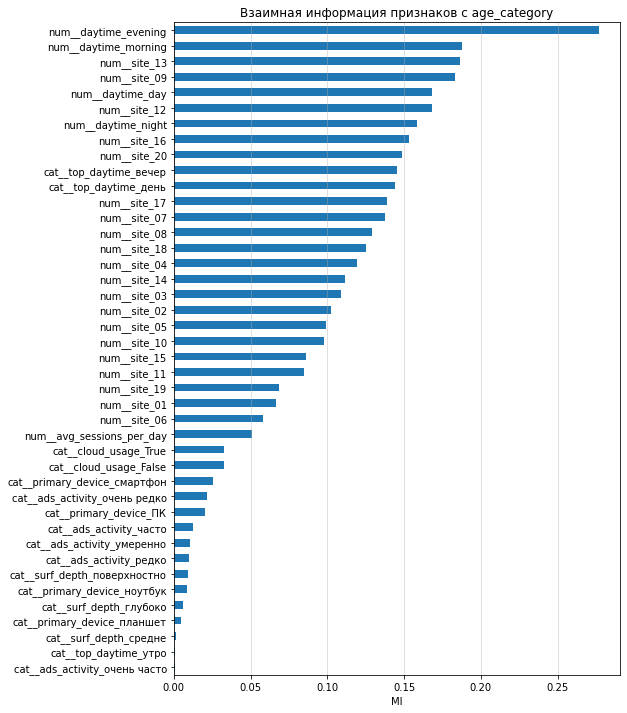

In [38]:
# Признаки train после препроцессора
X_train_prep = preprocessor.transform(X_train)

# Индексы числовых столбцов
num_idx = [i for i, name in enumerate(feature_names) if name.startswith('num__')]
cat_idx = [i for i, name in enumerate(feature_names) if name.startswith('cat__')]

# Взаимная информация
mi_num = mutual_info_classif(X_train_prep[:, num_idx], y_train, random_state=RANDOM_STATE)
mi_cat = mutual_info_classif(X_train_prep[:, cat_idx], y_train,
                             discrete_features=True, random_state=RANDOM_STATE)

mi_scores = pd.concat([
    pd.Series(mi_num, index=feature_names[num_idx]),
    pd.Series(mi_cat, index=feature_names[cat_idx])
]).sort_values(ascending=False)

display(mi_scores.round(3).to_frame('MI'))

# Столбчатая диаграмма
mi_scores.sort_values().plot(kind='barh', figsize=(8, 12))
plt.title('Взаимная информация признаков с age_category')
plt.xlabel('MI')
plt.grid(axis='x', alpha=0.5)
plt.show()

`MI` подтверждает ранжирование по `phik`. Сильнее всего с возрастом связаны `daytime_evening` (0.277), `daytime_morning` (0.188), `site_13` (0.186) и `site_09` (0.183), а слабее всех среди числовых признаков `avg_sessions_pre_day` (0.051). Выбор столбцов для удаления тоже подтверждается: `daytime_night` (0.158) слабее `daytime_day` (0.168), а `site_01` (0.066) вторая по слабости после `site_06` (0.058), поэтому из групп убираем `site_01` и `daytime_night`. Столбцы после `OHE` получили `MI` не выше 0.033, кроме `top_daytime_вечер` (0.145) и `top_daytime_день` (0.144). Окончательное решение по слабым признакам примем на кросс-валидации.

---

#### Встроенный метод: L1-регуляризация
Встроенные метода отбирают признаки в процессе обучения модели. В линейной модели вес показывает вклад признака, а L1-регуляризация (Lasso) добавляет к функции потерь штраф, пропорциональный сумме модулей весов. Чтобы уменьшить штраф, модель обнуляет веса у наименее полезных признаков. Фильтрация оценивала признаки по отдельности, а здесь отбор учитывает их совместную работу в модели.

`solver='liblinear'` поддерживает L1 и для нескольких классов работает по схеме One-vs-Rest. У каждого признака пять весов, по одному на класс. Признак считаем отброшенным, только если его веса равны нулю во всех пяти классах.

In [39]:
rows = []

for C in [100, 10, 1, 0.1, 0.01]:
    # L1-модель на предобработанном train
    l1_model = LogisticRegression(penalty='l1', solver='liblinear', C=C, random_state=RANDOM_STATE)
    l1_model.fit(X_train_prep, y_train)
    
    # Столбец остаётся, если вес ненулевой хотя бы у одного класса
    kept = pd.Series((l1_model.coef_ != 0).any(axis=0), index=feature_names)
    
    # Исходные признаки
    kept_num = [col for col in num_features if kept['num__' + col]]
    kept_cat = [col for col in cat_features if kept[kept.index.str.startswith('cat__' + col + '_')].any()]
    selected = kept_num + kept_cat
    dropped = [col for col in features if col not in selected]
    
    # CV: L1-модель на всех признаках
    l1_pipe = Pipeline([
        ('preprocessor', make_preprocessor(num_features, cat_features)),
        ('model', LogisticRegression(penalty='l1', solver='liblinear', C=C, random_state=RANDOM_STATE))
    ])
    res_l1 = cross_validate(l1_pipe, X_train[features], y_train, scoring=SCORING, cv=CV)
    
    # CV: baseline-модель на признаках, отобранных L1
    selected_pipe = Pipeline([
        ('preprocessor', make_preprocessor(kept_num, kept_cat)),
        ('model', LogisticRegression(multi_class='multinomial', solver='lbfgs', random_state=RANDOM_STATE))
    ])
    res_sel = cross_validate(selected_pipe, X_train[selected], y_train, scoring=SCORING, cv=CV)
    
    rows.append({
        'C': C,
        'нулевых столбцов из 42': (~kept).sum(),
        'признаков осталось из 30': len(selected),
        'f1_macro L1 (все признаки)': res_l1['test_f1_macro'].mean(),
        'f1_macro LR (отобранные)': res_sel['test_f1_macro'].mean(),
        'f1_std LR (отобранные)': res_sel['test_f1_macro'].std(),
        'отброшены': ', '.join(dropped) if dropped else '-'
    })
display(pd.DataFrame(rows).set_index('C').round(4))

,нулевых столбцов из 42,признаков осталось из 30,f1_macro L1 (все признаки),f1_macro LR (отобранные),f1_std LR (отобранные),отброшены
C,,,,,,
100.00,0,30,0.7922,0.8165,0.0077,-
10.00,1,30,0.7920,0.8165,0.0077,-
1.00,1,30,0.7914,0.8165,0.0077,-
0.10,2,30,0.7863,0.8165,0.0077,-
0.01,14,27,0.6670,0.8181,0.0079,"site_01, avg_sessions_per_day, ads_activity"


L1-модель на всех признаках оказалась заметно хуже baseline (0.7922 при `C=100` против 0.8165). Чтобы понять причину, сравним baseline с `liblinear` без L1 (с L2-штрафом) и с L1.

In [40]:
# Проверка, почему L1-модель хуже baseline
models = {
    'baseline: multinomial, lbfgs, L2': LogisticRegression(
        multi_class='multinomial', solver='lbfgs', random_state=RANDOM_STATE),
    'liblinear (OvR), L2, C=1': LogisticRegression(
        penalty='l2', solver='liblinear', C=1, random_state=RANDOM_STATE),
    'liblinear (OvR), L1, C=100': LogisticRegression(
        penalty='l1', solver='liblinear', C=100, random_state=RANDOM_STATE)
}

rows = []
for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', make_preprocessor(num_features, cat_features)),
        ('model', model)
    ])
    res = cross_validate(pipe, X_train[features], y_train, scoring=SCORING, cv=CV)
    rows.append({
        'модель': name,
        'f1_macro': res['test_f1_macro'].mean(),
        'f1_std': res['test_f1_macro'].std(),
        'precision_macro': res['test_precision_macro'].mean(),
        'recall_macro': res['test_recall_macro'].mean()
    })
display(pd.DataFrame(rows).set_index('модель').round(4))

,f1_macro,f1_std,precision_macro,recall_macro
модель,,,,
"baseline: multinomial, lbfgs, L2",0.8165,0.0077,0.8216,0.8133
"liblinear (OvR), L2, C=1",0.7923,0.0145,0.8154,0.7832
"liblinear (OvR), L1, C=100",0.7922,0.0149,0.8149,0.7831


При `C` от 100 до 0.1 `L1` не отбрасывает ни одного исходного признака (обнуляется 0-2 столбца из 42), поэтому набор и `F1 (macro)` совпадает с baseline (0.8165). При `C=0.01` отбрасывается `site_01`, `avg_sessions_per_day` и `ads_activity`: на оставшихся 27 признаках `F1 (macro)` = 0.8181 против 0.8165, разница меньше 1f1_std1 (0.0079), то есть качество не потеряно, но и не выросло. L1-модель на `liblinear` хуже baseline (0.7922), но дело не в L1. `liblinear` с L2-штрафом даёт те же 0.7923, поэтому L1 используем только как способ отбора. `site_01` и `avg_sessions_per_day` согласуются с предыдущими результатами (слабые по `phik` и `MI`), `ads_activity` (`phik` = 0.366) ему противоречит, поэтому решим по нему на кросс-валидации. Отбор и оценка идут по одному `CV`, поэтому оценка слегка опимистична.

### 8.2 Метод-обёртка: RFE
Методы-обёртки отбирают признаки по качеству модели на их подмножествах. `RFE` обучает логистическую регрессию на всех столбцах, удаляет столбец с наименьшим весом и повторяет это, пока не останется заданное число.

In [41]:
# RFE на предобработанном train
rfe = RFE(LogisticRegression(random_state=RANDOM_STATE), n_features_to_select=1, step=1)
rfe.fit(X_train_prep, y_train)

rfe_ranking = pd.Series(rfe.ranking_, index=feature_names).sort_values()

# Столбцы, исключённые первыми
display(rfe_ranking.tail(12).to_frame('ранг RFE'))

rows = []
for k in [42, 35, 30, 25, 20, 15, 10]:
    kept = rfe_ranking.index[rfe_ranking <= k]


    # Исходные признаки
    kept_num = [col for col in num_features if 'num__' + col in kept]
    kept_cat = [col for col in cat_features if any(name.startswith('cat__' + col + '_') for name in kept)]
    selected = kept_num + kept_cat
    dropped = [col for col in features if col not in selected]

    # CV
    rfe_pipe = Pipeline([
        ('preprocessor', make_preprocessor(kept_num, kept_cat)),
        ('model', LogisticRegression(random_state=RANDOM_STATE))
    ])
    res_rfe = cross_validate(rfe_pipe, X_train[selected], y_train, scoring=SCORING, cv=CV)

    rows.append({
        'столбцов из 42': k,
        'признаков осталось из 30': len(selected),
        'f1_macro': res_rfe['test_f1_macro'].mean(),
        'f1_std': res_rfe['test_f1_macro'].std(),
        'отброшены': ', '.join(dropped) if dropped else '-'
    })

display(pd.DataFrame(rows).set_index('столбцов из 42').round(4))

,ранг RFE
num__site_11,31
cat__surf_depth_поверхностно,32
cat__ads_activity_очень часто,33
cat__primary_device_ПК,34
cat__surf_depth_глубоко,35
cat__ads_activity_редко,36
num__site_05,37
cat__top_daytime_вечер,38
num__site_01,39
cat__surf_depth_средне,40


,признаков осталось из 30,f1_macro,f1_std,отброшены
столбцов из 42,,,,
42,30,0.8165,0.0077,-
35,27,0.8169,0.0072,"site_01, site_05, avg_sessions_per_day"
30,25,0.8159,0.0115,"site_01, site_05, site_11, avg_sessions_per_da..."
25,22,0.8054,0.0161,"site_01, site_05, site_06, site_11, site_14, s..."
20,18,0.7797,0.0167,"site_01, site_02, site_04, site_05, site_06, s..."
15,14,0.7690,0.0180,"site_01, site_02, site_04, site_05, site_06, s..."
10,9,0.6689,0.0146,"site_01, site_02, site_03, site_04, site_05, s..."


По `RFE`:
- при 35 столбцах из 42 `RFE` отбрасывает `site_01`, `site_05` и `avg_sessions_per_day`. `F1 (macro)` не падает (0.8169 против 0.8165 у baseline);
- при 30 столбцах качество ещё в пределах разброса по фолдам (0.8159, `f1_std` 0.0115);
- при 25 оно снижается (0.8054) и разброс растёт (0.0161);
- с 20 столбцов падение явное: от 0.7797 до 0.6689 при 10.

Первыми `RFE` исключает `site_01` и `avg_sessions_per_day`, что согласуется с `phik`, `MI` и L1, а `top_daytime_вечер` исключён рано, вероятно, потому что дублирует доли `daytime_*`. Ранг сравнивает веса масштабированных числовых столбцов и столбцов `OHE` (0/1) вместе, поэтому порядок исключения ориентировочный.

---

### 8.3 Выбор финального набора признаков
Сравним наборы, полученные разными методами, на той же `CV` с логистической регрессией (baseline).
- **без `site_01`, `daytime_night`:** по одному столбцу из групп долей, у которых связь с возрастом слабее по `phik` и `MI`;
- **+ без `avg_sessions_per_day`:** слабейший признак по `phik`, `MI`, `L1` и `RFE`;
- **+ без `ads_activity`:** проверка признака, который `L1` отбросил, а `phik` считал значимым;
- **L1 (`C=0.01`)** и **RFE (35 столбцов)**: набор встроенного метода и обёртки.

Финальный набор выбираем с учётом `F1 (macro)` и структуры признаков. В первую очередь исключаем по одному избыточному столбцу из групп долей `site_*` и `daytime_*`, затем проверяем, что качество не снизилось относительно baseline с учётом разброса `f1_std`. Дополнительное удаление признаков рассматриваем, если оно подтверждается несколькими методами и не ухудшает качество.

In [42]:
# Набор признаков
feature_sets = {
    'все признаки (baseline)': [],
    'без site_01, daytime_night': ['site_01', 'daytime_night'],
    '+ без avg_sessions_per_day': ['site_01', 'daytime_night', 'avg_sessions_per_day'],
    '+ без ads_activity': ['site_01', 'daytime_night', 'avg_sessions_per_day', 'ads_activity'],
    'L1 (C=0.01)': ['site_01', 'site_05', 'avg_sessions_per_day'],
    'RFE (35 столбцов)': ['site_01', 'site_05', 'avg_sessions_per_day']
}

rows = []
for name, drop_cols in feature_sets.items():
    num_cols = [col for col in num_features if col not in drop_cols]
    cat_cols = [col for col in cat_features if col not in drop_cols]

    # CV
    set_pipe = Pipeline([
        ('preprocessor', make_preprocessor(num_cols, cat_cols)),
        ('model', LogisticRegression(random_state=RANDOM_STATE))
    ])
    res_set = cross_validate(set_pipe, X_train[num_cols + cat_cols], y_train, scoring=SCORING, cv=CV)

    rows.append({
        'набор': name,
        'признаков': len(num_cols) + len(cat_cols),
        'f1_macro': res_set['test_f1_macro'].mean(),
        'f1_std': res_set['test_f1_macro'].std(),
        'precision_macro': res_set['test_precision_macro'].mean(),
        'recall_macro': res_set['test_recall_macro'].mean()
    })

display(pd.DataFrame(rows).set_index('набор').sort_values('f1_macro', ascending=False).round(4))

,признаков,f1_macro,f1_std,precision_macro,recall_macro
набор,,,,,
"без site_01, daytime_night",28,0.8183,0.0073,0.8245,0.8145
L1 (C=0.01),27,0.8169,0.0072,0.8224,0.8133
RFE (35 столбцов),27,0.8169,0.0072,0.8224,0.8133
все признаки (baseline),30,0.8165,0.0077,0.8216,0.8133
+ без avg_sessions_per_day,27,0.8157,0.0072,0.8225,0.8116
+ без ads_activity,26,0.8146,0.0084,0.8199,0.8111


**Вывод по отбору признаков.** Финальным выбираем набор без `site_01` и `daytime_night`: 28 признаков (23 числовых и 5 категориальных), `F1 (macro)` = 0.8183 против 0.8165 у baseline на 30 признаках. 

Прирост меньше `f1_std` (0.0073), поэтому качество не улучшилось, но и не потеряно, а полная мультиколлинеарность долей устранена. Наборы L1 (0.8181) и RFE (0.8169) от baseline тоже не отличаются в пределах разброса, а удаление `avg_sessions_per_day` и `ads_activity` даёт 0.8157 и 0.8146, поэтому эти признаки оставляем.

---

## 9. Подбор гиперпараметров моделей

### 9.1 Три подхода к многоклассовой классификации на логистической регрессии

Подбор ведём на финальном наборе из 8.3: 28 признаков (без `site_01` и `daytime_night`). Сравниваем три подхода:
- **One-vs-Rest (OvR):** пять бинарных моделей, класс против всех остальных;
- **One-vs-One (OvO):** десять бинарных моделей, по одной на каждую пару классов;
- **многоклассовая логистическая регрессия:** одна модель сразу на все пять классов.

In [43]:
# Финальный набор признаков
final_num_features = [col for col in num_features if col not in ['site_01', 'daytime_night']]
final_cat_features = cat_features
final_features = final_num_features + final_cat_features

# Сетка
C_VALUES = [0.01, 0.1, 1, 10, 100]
CLASS_WEIGHTS = [None, 'balanced']
grid_ovr = {'model__estimator__C': C_VALUES, 'model__estimator__class_weight': CLASS_WEIGHTS}
grid_multi = {'model__C': C_VALUES, 'model__class_weight': CLASS_WEIGHTS}

# Три подхода
approaches = {
    'OvR': (OneVsRestClassifier(LogisticRegression(max_iter=1000,random_state=RANDOM_STATE)), grid_ovr),
    'OvO': (OneVsOneClassifier(LogisticRegression(max_iter=1000,random_state=RANDOM_STATE)), grid_ovr),
    'multinomial': (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), grid_multi)
}

lr_results = []
lr_grids = {}
for name, (model, param_grid) in approaches.items():
    pipe = Pipeline([
        ('preprocessor', make_preprocessor(final_num_features, final_cat_features)),
        ('model', model)
    ])
    grid = GridSearchCV(pipe, param_grid=param_grid, cv=CV, scoring=SCORING, refit='f1_macro', n_jobs=-1)
    grid.fit(X_train[final_features], y_train)
    lr_grids[name] = grid

    # Метрики лучшей комбинации по фолдам
    i = grid.best_index_
    lr_results.append({
        'подход': name,
        'лучшие параметры': grid.best_params_,
        'f1_macro': grid.cv_results_['mean_test_f1_macro'][i],
        'f1_std': grid.cv_results_['std_test_f1_macro'][i],
        'precision_macro': grid.cv_results_['mean_test_precision_macro'][i],
        'recall_macro': grid.cv_results_['mean_test_recall_macro'][i]
    })

display(pd.DataFrame(lr_results).set_index('подход').round(4))

,лучшие параметры,f1_macro,f1_std,precision_macro,recall_macro
подход,,,,,
OvR,"{'model__estimator__C': 0.1, 'model__estimator...",0.8048,0.0066,0.8020,0.8095
OvO,"{'model__estimator__C': 1, 'model__estimator__...",0.8250,0.0088,0.8312,0.8210
multinomial,"{'model__C': 1, 'model__class_weight': None}",0.8183,0.0073,0.8245,0.8145


Лучший результат на `CV` у One-vs-One (`F1 (macro)` 0.8250, `C=1`), у многоклассовой логистической регрессии 0.8183 (`C=1`, `class_weight=None`), у One-vs-Rest 0.8048 (`C=0.1`). Отрыв OvO от `multinomial` (0.0067) меньше `f1_std` OvO (0.0088), поэтому эти два подхода пока считаем равноценными, а OvR заметно слабее обоих. Лучшие значения `C` лежат внутри сетки, расширять её не нужно. Позже сравним эти модели с `SVC` в одной общей таблице и выберем финальную.

---

### 9.2 SVC: подбор ядра и гиперпараметров

`SVC` строит разделяющую границу, а ядро задаёт её форму. `SVC` работает с пятью классами напрямую, обёртки `OneVsRestClassifier` и `OneVsOneClassifier` ему не нужны. `probability=True` не включаем: вероятности для `F1 (macro)` не нужны, а обучение с ними заметно дольше.

Сначала перебираем грубую сетку, затем уточняем её вокруг лучших значений. Набор признаков, `CV` и метрики те же, что в 9.1.

In [44]:
# Лучшая комбинация для каждого ядра
def show_best_by_kernel(search):
    cv_df = pd.DataFrame(search.cv_results_)
    table = (cv_df.sort_values('mean_test_f1_macro', ascending=False)
             .groupby('param_model__kernel').head(1)
             .set_index('param_model__kernel')
             [['params', 'mean_test_f1_macro', 'std_test_f1_macro',
               'mean_test_precision_macro', 'mean_test_recall_macro']]
             .rename(columns={'params': 'лучшие параметры',
                              'mean_test_f1_macro': 'f1_macro',
                              'std_test_f1_macro': 'f1_std',
                              'mean_test_precision_macro': 'precision_macro',
                              'mean_test_recall_macro': 'recall_macro'}))
    table.index.name = 'ядро'
    display(table.round(4))
    for kernel, row in table.iterrows():
        print(kernel, row['лучшие параметры'])
    return table


# Пайплайн
svc_pipe = Pipeline([
    ('preprocessor', make_preprocessor(final_num_features, final_cat_features)),
    ('model', SVC())
])

# Грубая сетка
svc_grid_coarse = [
    {'model__kernel': ['linear'], 'model__C': [0.1, 1, 10, 100]},
    {'model__kernel': ['rbf', 'sigmoid'], 'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 'auto']},
    {'model__kernel': ['poly'], 'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 'auto'], 'model__degree': [2, 3]}
]

svc_search = GridSearchCV(svc_pipe, param_grid=svc_grid_coarse, cv=CV, scoring=SCORING,
                          refit='f1_macro', n_jobs=-1)
svc_search.fit(X_train[final_features], y_train)

svc_by_kernel = show_best_by_kernel(svc_search)
print('Лучшая комбинация:', svc_search.best_params_)

/opt/conda/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/conda/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/conda/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/conda/lib/python3.9/site-packages/sklearn/metri

,лучшие параметры,f1_macro,f1_std,precision_macro,recall_macro
ядро,,,,,
rbf,"{'model__C': 10, 'model__gamma': 'auto', 'mode...",0.8902,0.0089,0.8938,0.8876
poly,"{'model__C': 1, 'model__degree': 2, 'model__ga...",0.8900,0.0058,0.8971,0.8844
linear,"{'model__C': 10, 'model__kernel': 'linear'}",0.8191,0.0103,0.8218,0.8177
sigmoid,"{'model__C': 1, 'model__gamma': 'auto', 'model...",0.7765,0.0095,0.7849,0.7726


rbf {'model__C': 10, 'model__gamma': 'auto', 'model__kernel': 'rbf'}
poly {'model__C': 1, 'model__degree': 2, 'model__gamma': 'scale', 'model__kernel': 'poly'}
linear {'model__C': 10, 'model__kernel': 'linear'}
sigmoid {'model__C': 1, 'model__gamma': 'auto', 'model__kernel': 'sigmoid'}
Лучшая комбинация: {'model__C': 10, 'model__gamma': 'auto', 'model__kernel': 'rbf'}


**Уточнение сетки.** По грубой сетке нелинейные ядра `rbf` (0.8902) и `poly` (0.8900) лучше остальных, а `linear` (0.8191) и `sigmoid` (0.7765) отбрасываем. Для `rbf` лучшая `gamma='auto'` (это `1 / число столбцов`, то есть малое значение), поэтому перебираем числовые значения `gamma` вокруг неё и `C` вокруг 10. Для `poly` оставляем `degree` 2 и 3 и добавляем `coef0`.

In [45]:
# Число столбцов после предобработки
print(len(svc_search.best_estimator_.named_steps['preprocessor'].get_feature_names_out()))

# Уточнённая сетка
svc_grid_fine = [
    {'model__kernel': ['rbf'], 'model__C': [3, 10, 30, 100],
     'model__gamma': [0.005, 0.01, 0.025, 0.05]},
    {'model__kernel': ['poly'], 'model__C': [0.3, 1, 3], 'model__degree': [2, 3],
     'model__gamma': ['scale'], 'model__coef0': [0.0, 0.5, 1.0]}
]

svc_search_fine = GridSearchCV(svc_pipe, param_grid=svc_grid_fine, cv=CV, scoring=SCORING,
                               refit='f1_macro', n_jobs=-1)
svc_search_fine.fit(X_train[final_features], y_train)

svc_fine_by_kernel = show_best_by_kernel(svc_search_fine)
print('Лучшая комбинация:', svc_search_fine.best_params_)

40


,лучшие параметры,f1_macro,f1_std,precision_macro,recall_macro
ядро,,,,,
rbf,"{'model__C': 3, 'model__gamma': 0.05, 'model__...",0.8955,0.0038,0.9017,0.8908
poly,"{'model__C': 0.3, 'model__coef0': 0.5, 'model_...",0.8935,0.0074,0.9012,0.8876


rbf {'model__C': 3, 'model__gamma': 0.05, 'model__kernel': 'rbf'}
poly {'model__C': 0.3, 'model__coef0': 0.5, 'model__degree': 3, 'model__gamma': 'scale', 'model__kernel': 'poly'}
Лучшая комбинация: {'model__C': 3, 'model__gamma': 0.05, 'model__kernel': 'rbf'}


По результатам уточнённого подбора гиперпараметров наилучшее значение `F1 (macro)` показала модель `SVC` с ядром `rbf` (`C=3`, `gamma=0.05`) равно 0.8955 при стандартном отклонении 0.0038. Модель с ядром `poly` показала близкий результат (0.8935), однако `rbf` имеет немного более высокую основную метрику и меньший разброс между фолдами, поэтому выбрана лучшей по результатам поиска. При этом разница между моделями невелика, а оценка качества на той же кросс-валидации, которая использовалась для подбора параметров, может быть несколько оптимистичной.

---

### 9.3. Сравнение моделей и выбор лучшей

На предыдущих этапах выполнен подбор гиперпараметров для трёх подходов к многоклассовой логистической регрессии и модели SVC с различными ядрами.

Для итогового сравнения объединим лучшие результаты в одну таблицу. Основной критерий выбора - `F1 (macro)`, дополнительными критериями служат стандартное отклонение метрики на кросс-валидации, `precision (macro)` и `recall (macro)`.

Сравнение проводится по результатам кросс-валидации на обучающей выборке. Тестовая выборка на данном этапе не используется.

In [46]:
# Результаты трёх подходов к логистической регрессии
lr_comparison = pd.DataFrame(lr_results).rename(columns={'подход': 'модель'})
lr_comparison['модель'] = 'LogisticRegression — ' + lr_comparison['модель']

# Результаты уточнённого подбора SVC
svc_comparison = svc_fine_by_kernel.reset_index().rename(columns={'ядро': 'модель'})
svc_comparison['модель'] = 'SVC — ' + svc_comparison['модель']

# Объединение и сортировка по основной метрике
model_comparison = pd.concat([lr_comparison, svc_comparison], ignore_index=True)
model_comparison = model_comparison.sort_values('f1_macro', ascending=False)

display(model_comparison.set_index('модель').round(4))

,лучшие параметры,f1_macro,f1_std,precision_macro,recall_macro
модель,,,,,
SVC — rbf,"{'model__C': 3, 'model__gamma': 0.05, 'model__...",0.8955,0.0038,0.9017,0.8908
SVC — poly,"{'model__C': 0.3, 'model__coef0': 0.5, 'model_...",0.8935,0.0074,0.9012,0.8876
LogisticRegression — OvO,"{'model__estimator__C': 1, 'model__estimator__...",0.8250,0.0088,0.8312,0.8210
LogisticRegression — multinomial,"{'model__C': 1, 'model__class_weight': None}",0.8183,0.0073,0.8245,0.8145
LogisticRegression — OvR,"{'model__estimator__C': 0.1, 'model__estimator...",0.8048,0.0066,0.8020,0.8095


По результатам кросс-валидации на обучающей выборке наилучшее качество показала модель `SVC` с ядром `rbf` и гиперпараметрами `C=3`, `gamma=0.05`: `F1 (macro)` = 0.8955 при стандартном отклонении 0.0038. Она превосходит лучший вариант логистической регрессии (`OvO`) на 0.0705 по `F1 (macro)`, а также имеет меньший разброс результатов между фолдами (0.0038 против 0.0088).

Модель `SVC` с ядром `poly` показала близкое качество (`F1 (macro)` = 0.8935). Тем не менее по основному критерию и стабильности результатов в проведённом сравнении выбрана `SVC` с ядром `rbf`. Оценка качества по кросс-валидации, использованной при подборе гиперпараметров, может быть несколько оптимистичной.

---

## 10. Подготовка артефактов модели для внедрения
По результатам подбора гиперпараметров выбрана модель `SVC` с ядром `rbf`, показавшая наилучшее значение `F1 (macro)` на кросс-валидации (0.8955).

Теперь обучим выбранную модель на всей обучающей выборке и оценим её качество на отложенной тестовой выборке, которая ранее не использовалась при обучении и подборе гиперпараметров. Рассмотрим метрики классификации, матрицу ошибок и особенности распознавания отдельных возрастных классов.

Затем сохраним обученный пайплайн предобработки и классификации, функцию формирования признаков и метаданные модели. Проверим, что после загрузки артефактов модель воспроизводит исходные предсказания.

### 10.1 Оценка лучшей модели на тестовой выборке

Для итоговой оценки используем лучшую комбинацию гиперпараметров, найденную с помощью `GridSearchCV`. Получим предсказания на тестовой выборке и рассчитаем метрики качества.

In [47]:
# Лучшая модель после подбора гиперпараметров
best_model = svc_search_fine.best_estimator_

# Предсказания на отложенной тестовой выборке
y_pred = best_model.predict(X_test[final_features])

# Метрики с разными способами усреднения
test_metrics = pd.DataFrame({
    'precision': [
        precision_score(y_test, y_pred, average=avg, zero_division=0)
        for avg in ['macro', 'micro', 'weighted']
    ],
    'recall': [
        recall_score(y_test, y_pred, average=avg, zero_division=0)
        for avg in ['macro', 'micro', 'weighted']
    ],
    'f1': [
        f1_score(y_test, y_pred, average=avg, zero_division=0)
        for avg in ['macro', 'micro', 'weighted']
    ]
}, index=['macro', 'micro', 'weighted'])

display(test_metrics.round(4))

# Подробные метрики по возрастным классам
print(classification_report(y_test, y_pred, zero_division=0))

,precision,recall,f1
macro,0.9027,0.8966,0.8994
micro,0.9176,0.9176,0.9176
weighted,0.9175,0.9176,0.9174


              precision    recall  f1-score   support

           0       0.94      0.92      0.93       213
           1       0.80      0.77      0.78       128
           2       0.90      0.94      0.92       360
           3       0.93      0.92      0.92       314
           4       0.95      0.95      0.95       442

    accuracy                           0.92      1457
   macro avg       0.90      0.90      0.90      1457
weighted avg       0.92      0.92      0.92      1457



На отложенной тестовой выборке из 1457 пользователей модель `SVC` с ядром `rbf` достигла `F1 (macro)` = 0.8994, что близко к результату кросс-валидации (0.8955). Это свидетельствует об отсутствии заметного снижения качества на тестовых данных.

Лучшее качество классификации получено для класса 4 (`F1` = 0.95), наименьшее - для класса 1 (`F1` = 0.78, `recall` = 0.77). Таким образом, несмотря на высокое общее качество, модель неодинаково точно распознаёт разные возрастные группы.

---

### 10.2 Анализ матрицы ошибок
Для более подробной оценки качества выбранной модели построим матрицу ошибок на тестовой выборке.

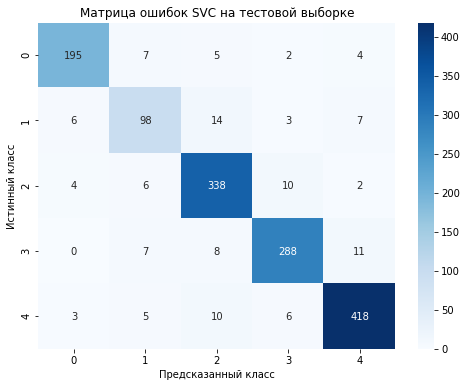

In [48]:
# Матрица ошибок на тестовой выборке
cm = confusion_matrix(y_test, y_pred)

# Визуализация матрицы ошибок
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title('Матрица ошибок SVC на тестовой выборке')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()

Матрица ошибок показала, что модель правильно классифицировала **1337 из 1457 пользователей (91.76%)**. Наибольшие значения правильных предсказаний относительно численности классов получены для классов 4 (94.57%) и 2 (93.89%), тогда как класс 1 распознаётся хуже остальных (76.56%).

Наиболее частая ошибка - отнесение пользователей класса 1 к классу 2 (14 случаев). Таким образом, модель демонстрирует высокое общее качество классификации, однако различия в точности распознавания отдельных возрастных групп необходимо учитывать при её практическом применении.

---

### 10.3 Сохранение модели и артефактов

Выбранная модель `SVC` с ядром `rbf` успешно прошла оценку на отложенной тестовой выборке. Значение основной метрики `F1 (macro)` составило 0.8994, что превышает установленный в задании порог 0.75.

Для последующего использования сохраним обученный пайплайн, объединяющий предобработку признаков и классификатор, с помощью `joblib`. Дополнительно сохраним метаданные: параметры модели, используемые признаки, метрики качества и версии основных библиотек.

Функция формирования признаков `build_features` уже находится в отдельном модуле `yeti_features.py`. Этот файл необходимо передавать вместе с моделью, чтобы воспроизводить преобразование исходных таблиц в признаковое пространство.

In [49]:
# Информация о признаках
features_info = {
    'input_features': final_features,
    'encoded_features': best_model.named_steps['preprocessor'].get_feature_names_out().tolist()
}

# Метаданные модели
metadata = {
    'model_version': '1.0',
    'training_date': pd.Timestamp.today().strftime('%Y-%m-%d'),
    'model': 'SVC (kernel=rbf, C=3, gamma=0.05)',
    'best_params': svc_search_fine.best_params_,
    'train_size': len(X_train),
    'test_size': len(X_test),
    'cv_f1_macro': svc_search_fine.best_score_,
    'test_metrics': test_metrics.to_dict(),
    'versions': {
        'sklearn': sklearn.__version__,
        'pandas': pd.__version__,
        'numpy': np.__version__
    }
}

# Артефакты
artifacts = {
    'pipeline': best_model,
    'features': features_info,
    'metadata': metadata
}

# Сохраняем в файл
joblib.dump(artifacts, 'yeti_age_model_v1.joblib')
print("Артефакты сохранены в файл 'yeti_age_model_v1.joblib'")

Артефакты сохранены в файл 'yeti_age_model_v1.joblib'


---

### 10.4 Проверка работоспособности сохранённых артефактов

Проверим, что сохранённая модель корректно загружается и воспроизводит предсказания исходного пайплайна. Для этого сохраним часть тестовой выборки и эталонные предсказания, полученные до загрузки модели. Затем создадим отдельный Python-скрипт, который загрузит артефакты и сравнит новые предсказания с эталонными.

Проверка будет выполнена в отдельном процессе Python, чтобы исключить зависимость от объектов, определённых в текущей сессии Jupyter. Качество модели повторно не оцениваем, проверяем только корректность сохранения и загрузки.

In [50]:
# Пользователи для проверки
X_check = X_test[final_features].head(1000)
check_users = data.loc[X_check.index, ID_COL].tolist()

# Эталонные предсказания до загрузки
pred_ref = best_model.predict(X_check)

# Исходные записи выбранных пользователей из шести таблиц
tables_check = {
    name: table[table[ID_COL].isin(check_users)].copy()
    for name, table in tables.items()
}

# Сохраняем исходные данные, порядок пользователей и предсказания
joblib.dump(tables_check, 'tables_check.joblib')
joblib.dump(check_users, 'check_users.joblib')
np.save('pred_ref.npy', pred_ref)

print('Проверочные данные и предсказания сохранены')

Проверочные данные и предсказания сохранены


In [51]:
%%writefile check_artifacts.py
import joblib
import numpy as np
import pandas as pd

from yeti_features import build_features

# Загружаем артефакты и исходные данные
artifacts = joblib.load('yeti_age_model_v1.joblib')
tables_check = joblib.load('tables_check.joblib')
check_users = joblib.load('check_users.joblib')
pred_ref = np.load('pred_ref.npy')

# Формируем признаки из шести исходных таблиц
data_check = build_features(tables_check)

# Восстанавливаем порядок пользователей
data_check = data_check.set_index('user_id').loc[check_users]

# Получаем предсказания загруженной модели
cols = artifacts['features']['input_features']
pred_new = artifacts['pipeline'].predict(data_check[cols])

# Сравниваем предсказания
comparison = pd.DataFrame({
    'до сохранения': pred_ref,
    'после загрузки': pred_new,
    'совпадение': pred_ref == pred_new
})

print(comparison.head(10))
print('Количество несовпадений:', (pred_ref != pred_new).sum())
print('Предсказания совпадают:', np.array_equal(pred_ref, pred_new))

Overwriting check_artifacts.py


In [52]:
import sys

!{sys.executable} check_artifacts.py

   до сохранения  после загрузки  совпадение
0              4               4        True
1              0               0        True
2              4               4        True
3              2               2        True
4              0               0        True
5              0               0        True
6              1               1        True
7              4               4        True
8              3               3        True
9              3               3        True
Количество несовпадений: 0
Предсказания совпадают: True


Обученный пайплайн `SVC` с предобработкой признаков, информация о признаках и метаданные модели успешно сохранены в файл `yeti_age_model_v1.joblib`. Проверка загрузки артефактов в отдельном процессе Python показала полное совпадение предсказаний с исходной моделью на 1000 наблюдениях (0 несовпадений).

Таким образом, сохранённый пайплайн корректно восстанавливается и готов к использованию для предсказаний на подготовленных признаках пользователей. Функция формирования признаков `build_features` хранится отдельно в модуле `yeti_features.py`.

---

## 11. Выводы о результатах работы

В ходе проекта разработана модель многоклассовой классификации пользователей компании "Йети" по возрастным категориям. Проведены исследовательский анализ данных, предобработка, создание и отбор признаков, сравнение алгоритмов классификации и подбор гиперпараметров.

**Основные результаты:**
- Лучшей моделью стала `SVC` с ядром `rbf` и параметрами `C=3`, `gamma=0.05`. На кросс-валидации она достигла **`F1 (macro)` = 0.8955**, на отложенной тестовой выборке - **0.8994**, превысив установленный порог **0.75**.
- Модель правильно определила возрастную категорию **1337 из 1457 пользователей (91.76%)**. Для важного с точки зрения бизнеса класса 0 (пользователи младше 18 лет) получены `precision = 0.94`, `recall = 0.92` и `F1 = 0.93`.
- Наименьшее качество получено для класса 1 (`F1 = 0.78`). Наиболее частая ошибка - отнесение пользователей этого класса к классу 2 (14 случаев). Это ограничение необходимо учитывать при практическом использовании модели.
- Обученный пайплайн с предобработкой и классификатором сохранён вместе с метаданными. Проверка в отдельном процессе Python подтвердила воспроизводимость полного пути от шести исходных таблиц до предсказаний: на 1000 пользователях получено **0 несовпадений**.

**Итог:** поставленная задача выполнена, требуемое качество классификации достигнуто. Модель может быть использована для определения возрастных категорий пользователей, однако перед практическим применением важно дополнительно оценить последствия ошибок для несовершеннолетних пользователей и проверить качество на новых данных.